# Klasifikasi Genre Novel dari Sinopsis: TF-IDF + ML Klasik vs BERT (versi FULL, data bersih)
### Replikasi dan perluasan dari paper: *Klasifikasi Genre Novel berdasarkan Sinopsis menggunakan Algoritma Random Forest* (Sistemasi, Vol. 15 No. 1, 2026)


In [1]:
!pip install -q transformers datasets accelerate scikit-learn nltk --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 69.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import os, re, time, gc, shutil, pickle, random, inspect, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
from nltk.stem import PorterStemmer   # algoritma murni, tanpa download

warnings.filterwarnings("ignore")

# ===================== KONFIGURASI =====================
SEED = 42
N_FOLDS = 5
RUN_BERT_SPLIT = True    # BERT pada split tetap (~17 menit di T4)
RUN_BERT_CV    = True    # BERT 5-fold CV (~75 menit di T4), bisa dilanjutkan jika terputus
BERT_NAME  = "bert-base-uncased"
MAX_LENGTH = 256
EPOCHS     = 5
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
# =======================================================

random.seed(SEED); np.random.seed(SEED)
stop_words = set(ENGLISH_STOP_WORDS)
stemmer = PorterStemmer()
print(f"Stopwords: {len(stop_words)} kata (scikit-learn) | SEED={SEED} | folds={N_FOLDS}")

Stopwords: 318 kata (scikit-learn) | SEED=42 | folds=5


## 1. Data: upload dan audit
Dataset Kaggle *Book Genre Prediction* (4.657 baris; kolom `index, title, genre, summary`). Simpan sebagai `data.csv`.

In [3]:
if not os.path.exists("data.csv"):
    from google.colab import files
    files.upload()   # pilih data.csv

df_raw = pd.read_csv("data.csv")
print("Bentuk data :", df_raw.shape)
print("Kolom       :", list(df_raw.columns))
print("\nMissing values:\n", df_raw.isnull().sum())
print("\nDistribusi genre (data asli):\n", df_raw['genre'].value_counts())

Saving data.csv to data.csv
Bentuk data : (4657, 4)
Kolom       : ['index', 'title', 'genre', 'summary']

Missing values:
 index      0
title      0
genre      0
summary    0
dtype: int64

Distribusi genre (data asli):
 genre
thriller      1023
fantasy        876
science        647
history        600
horror         600
crime          500
romance        111
psychology     100
sports         100
travel         100
Name: count, dtype: int64


In [4]:
# ---- Audit kualitas data + pembersihan ----
df_raw = df_raw.dropna(subset=['summary', 'genre']).reset_index(drop=True)
n_raw = len(df_raw)
dup_rows   = int(df_raw.duplicated(subset='summary', keep=False).sum())          # baris yang terlibat duplikat
n_conflict = int(df_raw.groupby('summary')['genre'].nunique().gt(1).sum())       # sinopsis dengan >1 label

# buang SEMUA baris yang sinopsisnya berlabel konflik, sisakan 1 dari duplikat berlabel sama
n_labels = df_raw.groupby('summary')['genre'].transform('nunique')
df = df_raw[n_labels == 1].drop_duplicates(subset='summary').reset_index(drop=True)

print(f"Data asli                 : {n_raw}")
print(f"Baris terlibat duplikat   : {dup_rows} ({dup_rows/n_raw*100:.1f}%)")
print(f"Sinopsis berlabel konflik : {n_conflict}")
print(f"Data setelah dibersihkan  : {len(df)}  (dibuang {n_raw-len(df)} baris = {(n_raw-len(df))/n_raw*100:.1f}%)")
cmp = pd.DataFrame({"asli": df_raw['genre'].value_counts(), "bersih": df['genre'].value_counts()})
cmp['dibuang (%)'] = ((cmp['asli'] - cmp['bersih']) / cmp['asli'] * 100).round(1)
display(cmp)

Data asli                 : 4657
Baris terlibat duplikat   : 228 (4.9%)
Sinopsis berlabel konflik : 96
Data setelah dibersihkan  : 4446  (dibuang 211 baris = 4.5%)


,asli,bersih,dibuang (%)
genre,,,
crime,500,500,0.0
fantasy,876,850,3.0
history,600,586,2.3
horror,600,571,4.8
psychology,100,87,13.0
romance,111,76,31.5
science,647,621,4.0
sports,100,80,20.0
thriller,1023,977,4.5


## 2. Preprocessing teks
Case folding, cleaning, tokenisasi, stopword removal, stemming (Porter). Data berbahasa Inggris, jadi tidak memakai Sastrawi.

In [5]:
# ==== Visualisasi tahap-demi-tahap praproses (model klasik) ====
contoh = df.iloc[[0, 1, 2]].copy()

def tahap_lower_clean(text):
    low = str(text).lower()
    return re.sub(r'[^a-z\s]', ' ', low)

def tahap_token_stopword_stem(cleaned):
    tokens = cleaned.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    return [stemmer.stem(t) for t in tokens]

rows = []
for _, r in contoh.iterrows():
    asli = r['summary']
    lower_clean = re.sub(r'\s+', ' ', tahap_lower_clean(asli)).strip()
    n_token_awal = len(lower_clean.split())
    token_akhir = tahap_token_stopword_stem(lower_clean)
    rows.append({
        "sinopsis_asli": asli[:150] + ("..." if len(asli) > 150 else ""),
        "setelah_lowercase_cleaning": lower_clean[:150] + ("..." if len(lower_clean) > 150 else ""),
        "hasil_token_stopword_stem": token_akhir,
        "jumlah_token_awal": n_token_awal,
        "jumlah_token_akhir": len(token_akhir),
    })

tabel_praproses_klasik = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
display(tabel_praproses_klasik)
tabel_praproses_klasik.to_csv("tabel_praproses_klasik.csv", index=False)

,sinopsis_asli,setelah_lowercase_cleaning,hasil_token_stopword_stem,jumlah_token_awal,jumlah_token_akhir
0,Drowned Wednesday is the first Trustee among the Morrow Days who is on Arthur's side and wishes the Will to be fulfilled. She appears as a leviathan/...,drowned wednesday is the first trustee among the morrow days who is on arthur s side and wishes the will to be fulfilled she appears as a leviathan wh...,"[drown, wednesday, truste, morrow, day, arthur, wish, fulfil, appear, leviathan, whale, suffer, gluttoni, book, begin, leaf, visit, arthur, discuss, invit, drown, wednesday, sent, arthur, admit, hospit, damag, leg, attempt, enter, tuesday, treasur, tower, suddenli, hospit, room, flood, water, transport, border, sea, hous, leaf, snatch, away, larg, ship, green, sail, known, fli, manti, arthur, remain, bed, medallion, given, immort, call, marin, appar, fail, summon, help, arthur, hope, eventu, buoy, mark, pirat, elishar, feverfew, treasur, float, soon, arthur, open, hand, mark, bloodi, red, colour, arthur, red, hand, feverfew, mark, treasur, identifi, later, long, scaveng, ship, call, moth, rescu, arthur, board, arthur, go, ...]",817,391
1,"As the book opens, Jason awakens on a school bus, unable to remember who or where he is, or anything about his past. He is sitting next to Piper McLe...",as the book opens jason awakens on a school bus unable to remember who or where he is or anything about his past he is sitting next to piper mclean an...,"[book, open, jason, awaken, school, bu, unabl, rememb, past, sit, piper, mclean, leo, valdez, say, girlfriend, best, friend, respect, class, field, trip, grand, canyon, arriv, classmat, dylan, turn, venti, storm, spirit, attack, trio, trip, leader, coach, gleeson, hedg, ensu, fight, jason, surpris, includ, coin, turn, sword, use, battl, storm, spirit, coach, hedg, reveal, satyr, fight, taken, captiv, flee, spirit, battl, fli, chariot, arriv, rescu, trio, peopl, annabeth, upset, discov, miss, boyfriend, perci, jackson, expect, annabeth, seek, perci, told, vision, goddess, hera, look, guy, shoe, turn, jason, shoe, destroy, fight, jason, piper, leo, told, demigod, taken, camp, half, blood, meet, greek, ...]",575,266
2,"Cugel is easily persuaded by the merchant Fianosther to attempt the burglary of the manse of Iucounu the Laughing Magician. Trapped and caught, he ag...",cugel is easily persuaded by the merchant fianosther to attempt the burglary of the manse of iucounu the laughing magician trapped and caught he agree...,"[cugel, easili, persuad, merchant, fianosth, attempt, burglari, mans, iucounu, laugh, magician, trap, caught, agre, exchang, freedom, undertak, recoveri, small, hemispher, violet, glass, eye, overworld, match, wizard, possess, small, sentient, alien, entiti, barb, hook, name, firx, attach, liver, encourag, unremit, loyalti, zeal, singl, purpos, iucounu, use, spell, transport, cugel, fli, demon, remot, land, cutz, cugel, find, villag, occupi, wearer, violet, lens, peasant, work, behalf, len, wearer, hope, promot, rank, lens, caus, wearer, squalid, surround, overworld, vastli, superior, version, realiti, hut, palac, gruel, magnific, feast, see, world, rose, color, glass, grand, scale, cugel, gain, eye, trickeri, escap, cutz, undertak, arduou, trek, iucounu, ...]",339,171


In [6]:
def preprocess_text(text):
    text = str(text).lower()                                            # case folding
    text = re.sub(r'[^a-z\s]', ' ', text)                               # cleaning
    tokens = text.split()                                               # tokenisasi
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]  # stopword removal
    tokens = [stemmer.stem(t) for t in tokens]                          # stemming
    return ' '.join(tokens)

t0 = time.time()
df['clean_summary'] = df['summary'].apply(preprocess_text)
print(f"Preprocessing selesai dalam {time.time()-t0:.0f} detik")
display(df[['summary', 'clean_summary']].head(3))

Preprocessing selesai dalam 25 detik


summary  \
0   Drowned Wednesday is the first Trustee among the Morrow Days who is on Arthur's side and wishes the Will to be fulfilled. She appears as a leviathan/whale and suffers from Gluttony. The book begins when Leaf is visiting Arthur and they are discussing the invitation that Drowned Wednesday sent him. Arthur had been admitted to hospital because of the damage done to his leg when he attempted to enter Tuesday's Treasure Tower. Suddenly, the hospital room becomes flooded with water as the two are transported to the Border Sea of the House. Leaf is snatched away by a large ship with green sails, known as the Flying Mantis, while Arthur remains in his bed. When the Medallion given him by the immortal called the Mariner apparently fails to summon help, Arthur is without hope. Eventually, a buoy marking the pirate Elishar Feverfew's treasure floats toward him. As soon as Arthur opens it, his hand is marked with a bloody red colour. Arthur now has the Red Hand, by which Feverfew marks whoever has found his treasure, so that he can identify them later. Not long after, a scavenging ship called the Moth rescues Arthur. On board, Arthur (going by the name of Arth) is introduced to Sunscorch, the First Mate, and to Captain Catapillow. Their journey brings them through the Line of Storms and into the Border Sea, where they are later pursued by Feverfew's ghostly ship, the Shiver. The damage inflicted on the Moth is serious; therefore Sunscorch commands an Upper House Sorcerer, Dr. Scamandros, to open a transfer portal to elsewhere in the Secondary Realms. Scamandros claims that Arthur is carrying something that interfered with his magic, and tells Sunscorch to throw him overboard. As a last resort, Arthur shows them the Mariner's Medallion, which stops Scamandros saying that they must get rid of Arthur. After going through the transfer portal (with Arthur's help), the ship is grounded on a beach. When Arthur wished to learn what happened to Leaf, Dr. Scamandros applies his sorcery to make it possible. She is revealed to be aboard the ship Flying Mantis. Arthur joins Catapillow for supper, later to reveal his identity. At first, Propaganda issued by Dame Primus (Arthur's Steward) makes them skeptical of this, but they eventually become convinced. A few days later, Wednesday's Dawn takes Arthur to meet Wednesday for her 'luncheon of seventeen removes'. As they approach, Wednesday shrinks into her human form to meet Arthur. During their lunch, Wednesday tells Arthur that after Part 3 of the Will has been released, she will surrender the Third Key to Arthur. Arthur is then taken by Wednesday's Dawn to a place called the triangle in search of his friend Leaf. He learns that Leaf has been forced to work on the Mantis, but is otherwise intact. Arthur later makes a deal with the Raised Rats, a group of anthropomorphic rats brought to the House by the Piper, to take him to Feverfew's hideout, which they believe is inside a miniature world located within Drowned Wednesday's stomach. On the Raised Rats' ship, Arthur opens a gift from Dr. Scamandros, which proves to be a golden transfer watch. With this, he communicates with and rescues Dr. Scamandros. He then uses a scrying mirror Dr. Scamandros gave him to watch Leaf. A rat watches him during the scry, and later saves him from a battle with Feverfew. Later, the Rats bring Arthur onto their submarine, where he meets with Suzy Turquiose Blue. In contrast to Suzy's former cockney attitude, she has assumed a more "ladylike and proper" demeanor on the orders of Dame Primus. Only when they are no longer on the Border Sea, but under it, does she resume her customary ways of speech and dress. They are, with navigational difficulty, able to enter the stomach of Lady Wednesday and the worldlet therein. There, Arthur and Suzy, disguised as rats, find escaped slaves, professed followers of the Carp. These exiles take them to the Carp, who is the third part of the Will. They are halted in their attem

## 3. Label dan split tetap (stratified 70/15/15)
Split ini identik untuk semua model pada bagian split tetap.

In [7]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['genre'])
label_names = le.classes_
num_labels = len(label_names)
print("Jumlah kelas:", num_labels, dict(enumerate(label_names)))

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)
print(f"\nTrain: {train_df.shape}  Val: {val_df.shape}  Test: {test_df.shape}")
print("\nDistribusi genre di train:\n", train_df['genre'].value_counts())
print("\nDistribusi genre di test :\n", test_df['genre'].value_counts())

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

Jumlah kelas: 10 {0: 'crime', 1: 'fantasy', 2: 'history', 3: 'horror', 4: 'psychology', 5: 'romance', 6: 'science', 7: 'sports', 8: 'thriller', 9: 'travel'}

Train: (3112, 6)  Val: (667, 6)  Test: (667, 6)

Distribusi genre di train:
 genre
thriller      684
fantasy       595
science       435
history       410
horror        400
crime         350
travel         68
psychology     61
sports         56
romance        53
Name: count, dtype: int64

Distribusi genre di test :
 genre
thriller      146
fantasy       128
science        93
history        88
horror         85
crime          75
travel         15
psychology     13
romance        12
sports         12
Name: count, dtype: int64


## 4. Fungsi bersama (evaluasi, penyimpanan hasil, uji McNemar)

In [8]:
results_summary = []   # ringkasan semua eksperimen split tetap
preds = {}             # prediksi tiap model pada test set tetap

def add_result(res):
    # simpan hasil; jika nama model sama, timpa (tidak ada baris ganda)
    global results_summary
    results_summary = [r for r in results_summary if r["model_name"] != res["model_name"]]
    results_summary.append(res)

def evaluate_model(y_true, y_pred, model_name, train_time=None, verbose=True):
    acc = accuracy_score(y_true, y_pred) * 100
    f1m = f1_score(y_true, y_pred, average='macro')
    kap = cohen_kappa_score(y_true, y_pred)
    if verbose:
        print(f"===== {model_name} =====")
        print(f"Accuracy   : {acc:.2f}%")
        print(f"F1 (macro) : {f1m:.3f}")
        print(f"Kappa      : {kap:.3f}")
        if train_time is not None:
            print(f"Waktu latih: {train_time:.1f} detik")
        print(classification_report(y_true, y_pred, target_names=label_names, zero_division=0))
    res = {"model_name": model_name, "accuracy": round(acc, 2), "f1_macro": round(f1m, 3),
           "kappa": round(kap, 3), "train_time_sec": round(train_time, 1) if train_time is not None else None}
    add_result(res)
    return res

def mcnemar_exact(y_true, pred_a, pred_b):
    # McNemar eksak (uji binomial) untuk dua model pada data yang sama
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    a_ok, b_ok = (pred_a == y_true), (pred_b == y_true)
    n01 = int(np.sum(a_ok & ~b_ok))     # A benar, B salah
    n10 = int(np.sum(~a_ok & b_ok))     # A salah, B benar
    n = n01 + n10
    p = binomtest(min(n01, n10), n, 0.5).pvalue if n > 0 else 1.0
    return n01, n10, p

## 5. Eksperimen A1: replikasi balancing paper (TF-IDF top-500 + Random Forest)
Paper melakukan `sample_n(size=100, replace=TRUE)` per genre pada data latih: kelas besar dipotong ke 100, kelas kecil digandakan.

In [ ]:
tfidf_500 = TfidfVectorizer(max_features=500)                       # top-500 fitur, mengikuti paper
X_train_500 = tfidf_500.fit_transform(train_df['clean_summary'])    # fit HANYA di data latih
X_test_500  = tfidf_500.transform(test_df['clean_summary'])

rng = np.random.RandomState(SEED)
bal_idx = []
for lbl in sorted(train_df['label'].unique()):
    idx_lbl = train_df.index[train_df['label'] == lbl].to_numpy()
    bal_idx.extend(rng.choice(idx_lbl, size=100, replace=True))
train_a1 = train_df.loc[bal_idx]
X_train_a1 = tfidf_500.transform(train_a1['clean_summary'])
y_train_a1 = train_a1['label'].values
print("Ukuran data latih A1 setelah balancing ala paper:", X_train_a1.shape)

t0 = time.time()
rf_a1 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train_a1, y_train_a1)
t_a1 = time.time() - t0
preds["A1: RF top500 (balancing paper)"] = rf_a1.predict(X_test_500)
evaluate_model(y_test, preds["A1: RF top500 (balancing paper)"], "A1: RF top500 (balancing paper)", train_time=t_a1);

Ukuran data latih A1 setelah balancing ala paper: (1000, 500)
===== A1: RF top500 (balancing paper) =====
Accuracy   : 45.88%
F1 (macro) : 0.422
Kappa      : 0.388
Waktu latih: 1.9 detik
              precision    recall  f1-score   support

       crime       0.47      0.72      0.57        75
     fantasy       0.73      0.38      0.50       128
     history       0.69      0.55      0.61        88
      horror       0.51      0.42      0.46        85
  psychology       0.23      0.46      0.31        13
     romance       0.19      0.75      0.31        12
     science       0.49      0.67      0.56        93
      sports       0.27      0.92      0.42        12
    thriller       0.40      0.16      0.23       146
      travel       0.18      0.53      0.27        15

    accuracy                           0.46       667
   macro avg       0.41      0.56      0.42       667
weighted avg       0.52      0.46      0.45       667



## 6. Eksperimen A2 dan A3: Random Forest tanpa balancing dan dengan class weight

In [ ]:
t0 = time.time()
rf_a2 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train_500, y_train)
t_a2 = time.time() - t0
preds["A2: RF top500 (tanpa balancing)"] = rf_a2.predict(X_test_500)
evaluate_model(y_test, preds["A2: RF top500 (tanpa balancing)"], "A2: RF top500 (tanpa balancing)", train_time=t_a2);

t0 = time.time()
rf_a3 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, class_weight='balanced').fit(X_train_500, y_train)
t_a3 = time.time() - t0
preds["A3: RF top500 (class_weight)"] = rf_a3.predict(X_test_500)
evaluate_model(y_test, preds["A3: RF top500 (class_weight)"], "A3: RF top500 (class_weight)", train_time=t_a3);

===== A2: RF top500 (tanpa balancing) =====
Accuracy   : 60.42%
F1 (macro) : 0.424
Kappa      : 0.520
Waktu latih: 8.7 detik
              precision    recall  f1-score   support

       crime       0.71      0.47      0.56        75
     fantasy       0.64      0.73      0.68       128
     history       0.72      0.73      0.72        88
      horror       0.80      0.38      0.51        85
  psychology       0.00      0.00      0.00        13
     romance       1.00      0.17      0.29        12
     science       0.67      0.69      0.68        93
      sports       0.00      0.00      0.00        12
    thriller       0.46      0.75      0.57       146
      travel       0.67      0.13      0.22        15

    accuracy                           0.60       667
   macro avg       0.57      0.40      0.42       667
weighted avg       0.63      0.60      0.58       667

===== A3: RF top500 (class_weight) =====
Accuracy   : 61.77%
F1 (macro) : 0.586
Kappa      : 0.553
Waktu latih: 7.4 

## 7. A4 & A5: RF kosakata penuh (1-2gram) pada pembagian tetap -- pasangan non-CV dari cv_rf_full


In [ ]:
# A4 & A5: RF kosakata penuh (1-2gram) pada pembagian tetap -- pasangan non-CV dari cv_rf_full

t0 = time.time()
rf_full_nobal = RandomForestClassifier(n_estimators=300, class_weight=None,
                                       random_state=SEED, n_jobs=-1).fit(X_train_full, y_train)
t_a4 = time.time() - t0
preds["A4: RF vocab penuh (tanpa balancing)"] = rf_full_nobal.predict(X_test_full)
evaluate_model(y_test, preds["A4: RF vocab penuh (tanpa balancing)"],
               "A4: RF vocab penuh (tanpa balancing)", train_time=t_a4);

t0 = time.time()
rf_full_cw = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=SEED, n_jobs=-1).fit(X_train_full, y_train)
t_a5 = time.time() - t0
preds["A5: RF vocab penuh (class_weight)"] = rf_full_cw.predict(X_test_full)
evaluate_model(y_test, preds["A5: RF vocab penuh (class_weight)"],
               "A5: RF vocab penuh (class_weight)", train_time=t_a5);

===== A4: RF vocab penuh (tanpa balancing) =====
Accuracy   : 61.47%
F1 (macro) : 0.426
Kappa      : 0.530
Waktu latih: 23.3 detik
              precision    recall  f1-score   support

       crime       0.74      0.39      0.51        75
     fantasy       0.56      0.89      0.69       128
     history       0.82      0.62      0.71        88
      horror       0.90      0.33      0.48        85
  psychology       1.00      0.08      0.14        13
     romance       0.00      0.00      0.00        12
     science       0.77      0.67      0.71        93
      sports       1.00      0.25      0.40        12
    thriller       0.49      0.81      0.61       146
      travel       0.00      0.00      0.00        15

    accuracy                           0.61       667
   macro avg       0.63      0.40      0.43       667
weighted avg       0.67      0.61      0.59       667

===== A5: RF vocab penuh (class_weight) =====
Accuracy   : 65.97%
F1 (macro) : 0.646
Kappa      : 0.598
Waktu 

## 8. Eksperimen B1 dan B2: Logistic Regression dan SVM (TF-IDF top-500, class weight)

In [ ]:
t0 = time.time()
lr = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train_500, y_train)
t_lr = time.time() - t0
preds["B1: LR top500"] = lr.predict(X_test_500)
evaluate_model(y_test, preds["B1: LR top500"], "B1: LR top500", train_time=t_lr);

t0 = time.time()
svm = LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED).fit(X_train_500, y_train)
t_svm = time.time() - t0
preds["B2: SVM top500"] = svm.predict(X_test_500)
evaluate_model(y_test, preds["B2: SVM top500"], "B2: SVM top500", train_time=t_svm);

===== B1: LR top500 =====
Accuracy   : 64.92%
F1 (macro) : 0.612
Kappa      : 0.593
Waktu latih: 0.3 detik
              precision    recall  f1-score   support

       crime       0.63      0.75      0.68        75
     fantasy       0.75      0.69      0.72       128
     history       0.71      0.76      0.73        88
      horror       0.55      0.54      0.54        85
  psychology       0.43      0.77      0.56        13
     romance       0.36      0.67      0.47        12
     science       0.73      0.70      0.71        93
      sports       0.48      0.83      0.61        12
    thriller       0.71      0.50      0.59       146
      travel       0.42      0.67      0.51        15

    accuracy                           0.65       667
   macro avg       0.58      0.69      0.61       667
weighted avg       0.67      0.65      0.65       667

===== B2: SVM top500 =====
Accuracy   : 62.82%
F1 (macro) : 0.597
Kappa      : 0.565
Waktu latih: 0.2 detik
              precision   

## 9. Eksperimen B3 dan B4: baseline klasik kuat (TF-IDF vocab penuh +

1-2gram)
Batas 500 fitur warisan paper melemahkan model klasik. Bagian ini memberi pembanding yang adil untuk BERT.

In [ ]:
tf_full = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_full = tf_full.fit_transform(train_df['clean_summary'])     # fit HANYA di data latih
X_test_full  = tf_full.transform(test_df['clean_summary'])
print("Ukuran vocab penuh:", X_train_full.shape[1], "fitur")

t0 = time.time()
lr_full = LogisticRegression(C=10, max_iter=3000, class_weight='balanced').fit(X_train_full, y_train)
t_b3 = time.time() - t0
preds["B3: LR vocab penuh"] = lr_full.predict(X_test_full)
evaluate_model(y_test, preds["B3: LR vocab penuh"], "B3: LR vocab penuh", train_time=t_b3);

t0 = time.time()
svm_full = LinearSVC(C=0.5, class_weight='balanced', max_iter=5000, random_state=SEED).fit(X_train_full, y_train)
t_b4 = time.time() - t0
preds["B4: SVM vocab penuh"] = svm_full.predict(X_test_full)
evaluate_model(y_test, preds["B4: SVM vocab penuh"], "B4: SVM vocab penuh", train_time=t_b4);

Ukuran vocab penuh: 57147 fitur
===== B3: LR vocab penuh =====
Accuracy   : 74.96%
F1 (macro) : 0.745
Kappa      : 0.703
Waktu latih: 9.9 detik
              precision    recall  f1-score   support

       crime       0.75      0.69      0.72        75
     fantasy       0.78      0.88      0.83       128
     history       0.82      0.84      0.83        88
      horror       0.62      0.62      0.62        85
  psychology       0.89      0.62      0.73        13
     romance       0.89      0.67      0.76        12
     science       0.82      0.78      0.80        93
      sports       1.00      0.67      0.80        12
    thriller       0.67      0.70      0.68       146
      travel       0.75      0.60      0.67        15

    accuracy                           0.75       667
   macro avg       0.80      0.71      0.75       667
weighted avg       0.75      0.75      0.75       667

===== B4: SVM vocab penuh =====
Accuracy   : 76.01%
F1 (macro) : 0.769
Kappa      : 0.717
Waktu l

## 10. BERT: definisi fungsi (dipakai untuk split tetap dan CV)
Imbalance ditangani dengan *weighted cross-entropy* (bobot dihitung dari data latih tiap run). Checkpoint dihapus setelah tiap run agar disk Colab tidak penuh.

In [9]:
import torch
import torch.nn as nn
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print("Device:", device)
if (RUN_BERT_SPLIT or RUN_BERT_CV) and device.type != "cuda":
    print("PERINGATAN: GPU tidak aktif. Ganti runtime ke T4 GPU sebelum menjalankan BERT.")

tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer(b['summary'], truncation=True, padding='max_length', max_length=MAX_LENGTH), batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=self.class_weights)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def bert_metrics(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def make_training_args(out_dir, n_train):
    params = inspect.signature(TrainingArguments.__init__).parameters   # kompatibel lintas versi transformers
    kw = dict(output_dir=out_dir, learning_rate=LEARNING_RATE,
              per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=32,
              num_train_epochs=EPOCHS, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
              seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params:         kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params:         kw["save_strategy"] = "epoch"
    if "save_total_limit" in params:      kw["save_total_limit"] = 1
    if "warmup_ratio" in params:          kw["warmup_ratio"] = 0.1
    elif "warmup_steps" in params:        kw["warmup_steps"] = int(0.1 * (n_train // BATCH_SIZE) * EPOCHS)
    return TrainingArguments(**kw)

def run_bert(train_part, val_part, test_part, tag):
    # latih BERT di train_part, early stopping di val_part, prediksi test_part
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds(train_part), to_ds(val_part), to_ds(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=num_labels).to(device)
    out_dir = f"./bert_{tag}"
    trainer = WeightedTrainer(model=model, args=make_training_args(out_dir, len(tr)),
                              train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics,
                              callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
                              class_weights=w)
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer
    gc.collect(); torch.cuda.empty_cache(); shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

Device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [10]:
# ==== Visualisasi tokenisasi WordPiece + padding/truncation (BERT) ====
contoh_bert = df.iloc[[0, 1, 2]].copy()

rows_bert = []
for _, r in contoh_bert.iterrows():
    asli = r['summary']
    toks = tokenizer.tokenize(asli)
    enc = tokenizer(asli, truncation=True, padding='max_length', max_length=MAX_LENGTH)
    rows_bert.append({
        "sinopsis_asli": asli[:150] + ("..." if len(asli) > 150 else ""),
        "contoh_subtoken_wordpiece": toks[:15] + (["..."] if len(toks) > 15 else []),
        "jumlah_token_sebelum_padding": len(toks),
        "contoh_input_ids_setelah_padding": enc["input_ids"][:15] + (["..."] if len(enc["input_ids"]) > 15 else []),
        "panjang_setelah_padding": len(enc["input_ids"]),
    })

tabel_tokenisasi_bert = pd.DataFrame(rows_bert)
display(tabel_tokenisasi_bert)
tabel_tokenisasi_bert.to_csv("tabel_tokenisasi_bert.csv", index=False)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1064 > 512). Running this sequence through the model will result in indexing errors


,sinopsis_asli,contoh_subtoken_wordpiece,jumlah_token_sebelum_padding,contoh_input_ids_setelah_padding,panjang_setelah_padding
0,Drowned Wednesday is the first Trustee among the Morrow Days who is on Arthur's side and wishes the Will to be fulfilled. She appears as a leviathan/...,"[drowned, wednesday, is, the, first, trustee, among, the, morrow, days, who, is, on, arthur, ', ...]",1064,"[101, 12805, 9317, 2003, 1996, 2034, 13209, 2426, 1996, 19084, 2420, 2040, 2003, 2006, 4300, ...]",256
1,"As the book opens, Jason awakens on a school bus, unable to remember who or where he is, or anything about his past. He is sitting next to Piper McLe...","[as, the, book, opens, ,, jason, awake, ##ns, on, a, school, bus, ,, unable, to, ...]",719,"[101, 2004, 1996, 2338, 7480, 1010, 4463, 8300, 3619, 2006, 1037, 2082, 3902, 1010, 4039, ...]",256
2,"Cugel is easily persuaded by the merchant Fianosther to attempt the burglary of the manse of Iucounu the Laughing Magician. Trapped and caught, he ag...","[cu, ##gel, is, easily, persuaded, by, the, merchant, fia, ##nos, ##ther, to, attempt, the, bu, ...]",478,"[101, 12731, 12439, 2003, 4089, 11766, 2011, 1996, 6432, 19807, 15460, 12399, 2000, 3535, 1996, ...]",256


## 11. Eksperimen C: fine-tuning BERT pada split tetap

In [ ]:
# [CELL:bert_split]
if RUN_BERT_SPLIT:
    r = run_bert(train_df, val_df, test_df, "split")
    assert (r["y_true"] == y_test).all(), "urutan test tidak sama"
    preds["C: BERT"] = r["y_pred"]
    evaluate_model(y_test, preds["C: BERT"], "C: BERT", train_time=r["time_sec"]);
else:
    print("RUN_BERT_SPLIT=False: BERT split tetap dilewati.")

Map:   0%|          | 0/3112 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

===== C: BERT =====
Accuracy   : 80.21%
F1 (macro) : 0.839
Kappa      : 0.767
Waktu latih: 801.6 detik
              precision    recall  f1-score   support

       crime       0.83      0.72      0.77        75
     fantasy       0.83      0.82      0.82       128
     history       0.75      0.86      0.80        88
      horror       0.66      0.73      0.69        85
  psychology       0.93      1.00      0.96        13
     romance       0.79      0.92      0.85        12
     science       0.82      0.81      0.82        93
      sports       0.92      1.00      0.96        12
    thriller       0.85      0.78      0.81       146
      travel       0.93      0.87      0.90        15

    accuracy                           0.80       667
   macro avg       0.83      0.85      0.84       667
weighted avg       0.81      0.80      0.80       667



## 12. Confusion matrix semua model (split tetap)


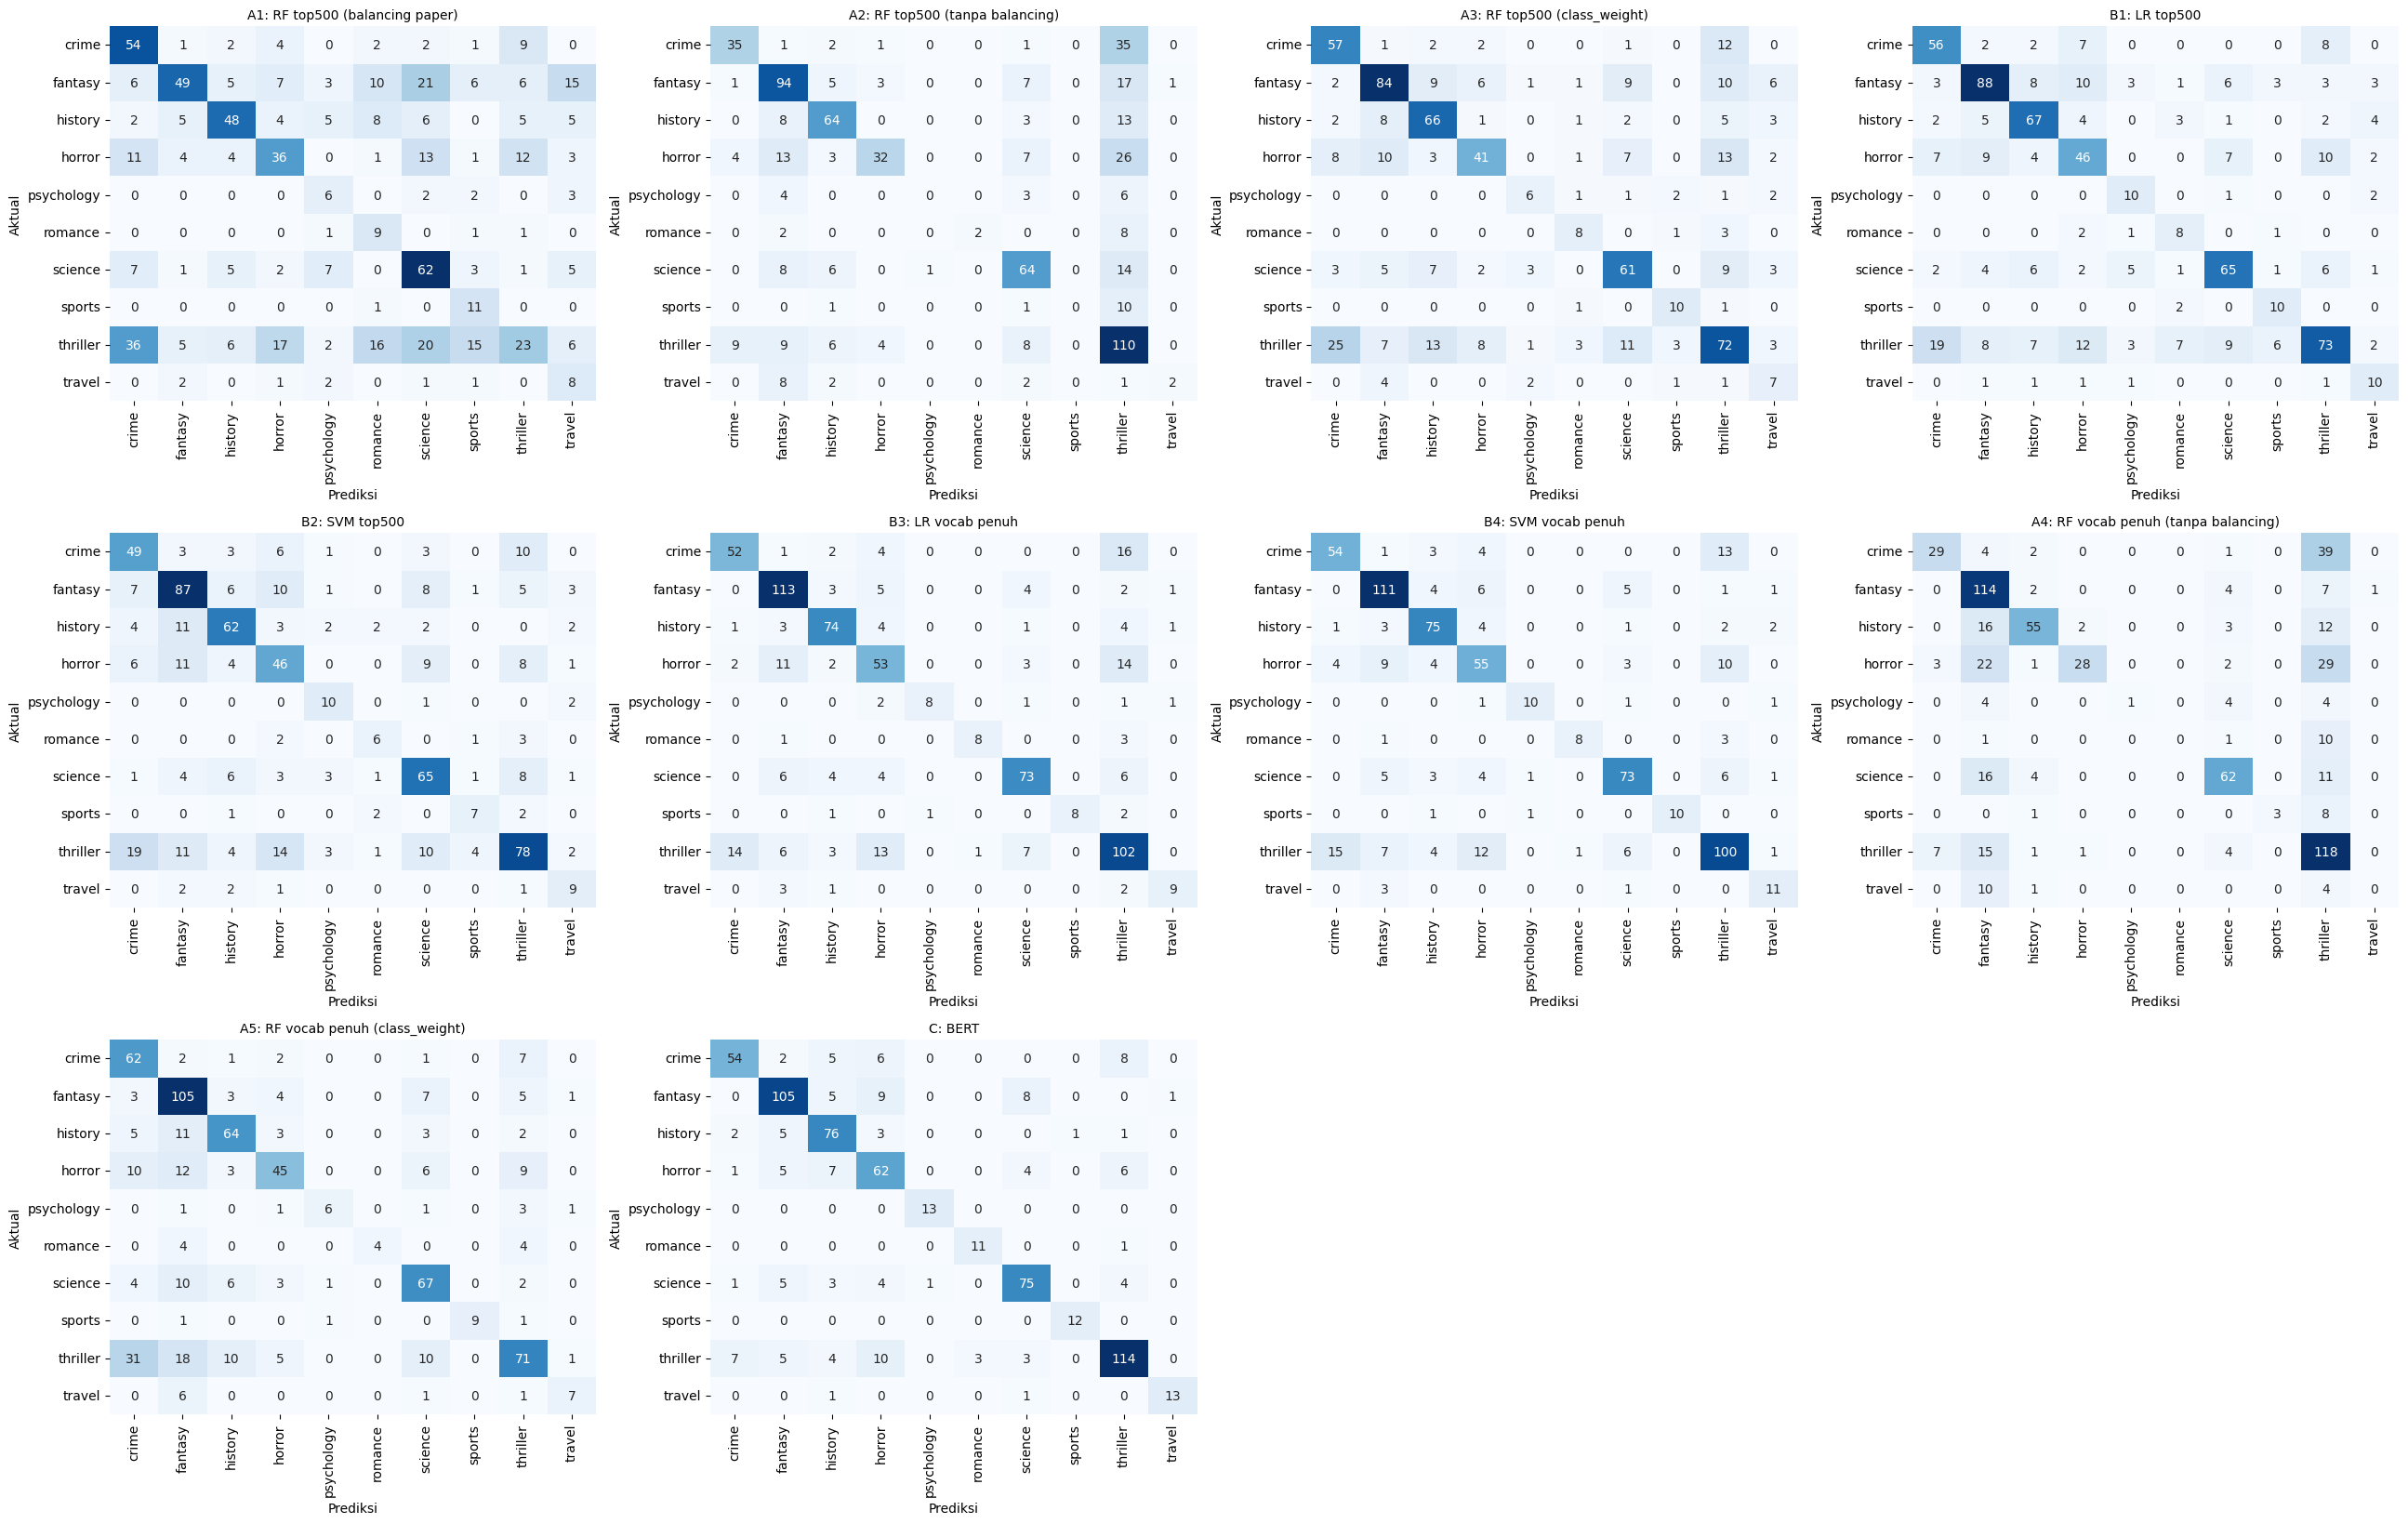

In [ ]:
names = list(preds.keys())
ncol = 4
nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6.5 * ncol, 5.5 * nrow))
axes = np.array(axes).reshape(-1)
for ax, name in zip(axes, names):
    cm = confusion_matrix(y_test, preds[name], labels=np.arange(num_labels))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=label_names, yticklabels=label_names)
    ax.set_title(name, fontsize=10); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
for ax in axes[len(names):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 13. Uji signifikansi McNemar pada split tetap (BERT vs model lain)

In [ ]:
if "C: BERT" in preds:
    rows = []
    for ref in [k for k in preds if k != "C: BERT"]:
        n01, n10, p = mcnemar_exact(y_test, preds["C: BERT"], preds[ref])
        rows.append({"BERT vs": ref, "BERT benar / lawan salah": n01, "kebalikannya": n10, "p-value": f"{p:.3g}",
                     "signifikan (p<0.05)": "ya" if p < 0.05 else "tidak"})
    display(pd.DataFrame(rows))
else:
    print("BERT split tetap belum dijalankan.")

,BERT vs,BERT benar / lawan salah,kebalikannya,p-value,signifikan (p<0.05)
0,A1: RF top500 (balancing paper),262,33,2.06e-45,ya
1,A2: RF top500 (tanpa balancing),175,43,4.37e-20,ya
2,A3: RF top500 (class_weight),170,47,1.51e-17,ya
3,B1: LR top500,147,45,7.82e-14,ya
4,B2: SVM top500,161,45,1.65e-16,ya
5,B3: LR vocab penuh,85,50,0.00328,ya
6,B4: SVM vocab penuh,74,46,0.0134,ya
7,A4: RF vocab penuh (tanpa balancing),175,50,1.9e-17,ya
8,A5: RF vocab penuh (class_weight),145,50,6.37e-12,ya


## 13. Tabel perbandingan akhir (split tetap) dan peningkatan terhadap paper
Angka paper memakai subset 1.000 baris dengan data uji sekitar 195 sampel, jadi **tidak sebanding langsung**; dikutip untuk konteks.

,model_name,accuracy,f1_macro,kappa,train_time_sec,sumber
0,C: BERT,80.21,0.839,0.767,801.6,"kami (data bersih, split tetap)"
1,B4: SVM vocab penuh,76.01,0.769,0.717,0.3,"kami (data bersih, split tetap)"
2,B3: LR vocab penuh,74.96,0.745,0.703,7.3,"kami (data bersih, split tetap)"
3,A5: RF vocab penuh (class_weight),65.97,0.646,0.598,20.3,"kami (data bersih, split tetap)"
4,B1: LR top500,64.92,0.612,0.593,0.2,"kami (data bersih, split tetap)"
5,B2: SVM top500,62.82,0.597,0.565,0.2,"kami (data bersih, split tetap)"
6,A3: RF top500 (class_weight),61.77,0.586,0.553,7.8,"kami (data bersih, split tetap)"
7,Paper: RF top500 (sesudah balancing manual),46.67,0.443,0.387,NaN,paper (subset 1000)
8,A4: RF vocab penuh (tanpa balancing),61.47,0.426,0.530,23.3,"kami (data bersih, split tetap)"
9,A2: RF top500 (tanpa balancing),60.42,0.424,0.520,17.2,"kami (data bersih, split tetap)"


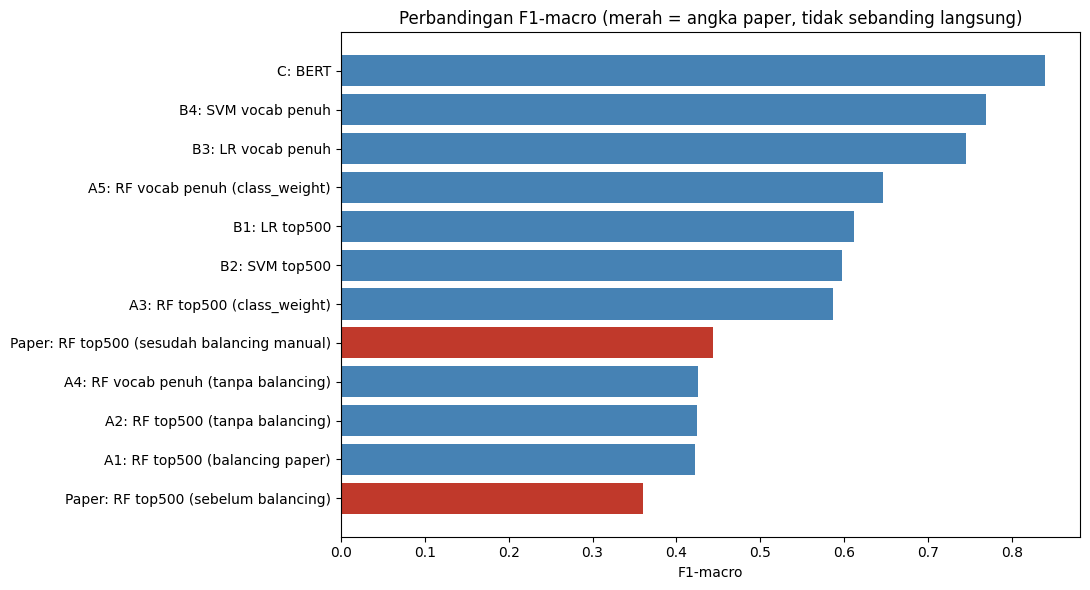

,model_name,accuracy,f1_macro,kappa,d accuracy (poin),d accuracy (%),d f1_macro (selisih),d f1_macro (%),d kappa (selisih),d kappa (%)
0,A1: RF top500 (balancing paper),45.88,0.422,0.388,-0.79,-1.7,-0.021,-4.7,0.001,0.3
1,A2: RF top500 (tanpa balancing),60.42,0.424,0.520,13.75,29.5,-0.019,-4.3,0.133,34.4
2,A3: RF top500 (class_weight),61.77,0.586,0.553,15.10,32.4,0.143,32.3,0.166,42.9
3,B1: LR top500,64.92,0.612,0.593,18.25,39.1,0.169,38.1,0.206,53.2
4,B2: SVM top500,62.82,0.597,0.565,16.15,34.6,0.154,34.8,0.178,46.0
5,B3: LR vocab penuh,74.96,0.745,0.703,28.29,60.6,0.302,68.2,0.316,81.7
6,B4: SVM vocab penuh,76.01,0.769,0.717,29.34,62.9,0.326,73.6,0.330,85.3
7,A4: RF vocab penuh (tanpa balancing),61.47,0.426,0.530,14.80,31.7,-0.017,-3.8,0.143,37.0
8,A5: RF vocab penuh (class_weight),65.97,0.646,0.598,19.30,41.4,0.203,45.8,0.211,54.5
9,C: BERT,80.21,0.839,0.767,33.54,71.9,0.396,89.4,0.380,98.2


In [ ]:
paper_baseline = [
    {"model_name": "Paper: RF top500 (sebelum balancing)", "accuracy": 42.11, "f1_macro": 0.360, "kappa": 0.310, "train_time_sec": None},
    {"model_name": "Paper: RF top500 (sesudah balancing manual)", "accuracy": 46.67, "f1_macro": 0.443, "kappa": 0.387, "train_time_sec": None},
]
ours = pd.DataFrame(results_summary); ours['sumber'] = 'kami (data bersih, split tetap)'
paper_df = pd.DataFrame(paper_baseline); paper_df['sumber'] = 'paper (subset 1000)'
final_comparison = pd.concat([paper_df, ours], ignore_index=True).sort_values('f1_macro', ascending=False).reset_index(drop=True)
display(final_comparison)

plt.figure(figsize=(11, 6))
colors = ['#c0392b' if s.startswith('paper') else 'steelblue' for s in final_comparison['sumber']]
plt.barh(final_comparison['model_name'], final_comparison['f1_macro'], color=colors)
plt.xlabel('F1-macro'); plt.title('Perbandingan F1-macro (merah = angka paper, tidak sebanding langsung)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

ref = {"accuracy": 46.67, "f1_macro": 0.443, "kappa": 0.387}     # hasil terbaik paper
imp = ours[['model_name', 'accuracy', 'f1_macro', 'kappa']].copy()
for m, unit in [("accuracy", "poin"), ("f1_macro", "selisih"), ("kappa", "selisih")]:
    imp[f"d {m} ({unit})"] = (imp[m] - ref[m]).round(3)
    imp[f"d {m} (%)"] = ((imp[m] / ref[m] - 1) * 100).round(1)
display(imp)

# BAGIAN CV: 5-fold cross validation (fold identik untuk semua model)
Semua model dievaluasi pada seluruh data bersih dengan `StratifiedKFold(5, shuffle=True, random_state=SEED)`.
TF-IDF di-fit **hanya** di data latih tiap fold. Prediksi out-of-fold disimpan untuk uji McNemar dan analisis per-genre.

In [ ]:
# [CELL:cv_klasik]
y_all = df['label'].values
X_txt = df['clean_summary'].values
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(df.index.values, y_all))      # dipakai BERT CV juga -> fold identik

def make_models():
    return {
        "RF  (top500, tanpa balancing)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        "RF  (top500, class_weight)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))]),
        "LR  (top500, class_weight)": Pipeline([("tf", TfidfVectorizer(max_features=500)),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "LR  (vocab penuh, 1-2gram)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", LogisticRegression(C=10, max_iter=3000, class_weight="balanced"))]),
        "SVM (vocab penuh, 1-2gram)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", LinearSVC(C=0.5, class_weight="balanced", max_iter=5000, random_state=SEED))]),
        "A4: RF vocab penuh (tanpa balancing)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight=None, random_state=SEED, n_jobs=-1))]),
        "A5: RF vocab penuh (class_weight)": Pipeline([("tf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1))]),
    }

oof_pred = {name: np.zeros(len(df), dtype=int) for name in make_models()}
cv_rows = []
for fold, (tr, te) in enumerate(folds, start=1):
    for name, model in make_models().items():
        t0 = time.time()
        model.fit(X_txt[tr], y_all[tr])
        p = model.predict(X_txt[te])
        oof_pred[name][te] = p
        cv_rows.append({"model": name, "fold": fold, "acc": accuracy_score(y_all[te], p) * 100,
                        "f1_macro": f1_score(y_all[te], p, average="macro"),
                        "kappa": cohen_kappa_score(y_all[te], p), "time_sec": time.time() - t0})
    print(f"fold {fold}/{N_FOLDS} selesai")
cv_klasik = pd.DataFrame(cv_rows)
display(cv_klasik.groupby("model")[["acc", "f1_macro", "kappa"]].agg(["mean", "std"]).round(3))

fold 1/5 selesai
fold 2/5 selesai
fold 3/5 selesai
fold 4/5 selesai
fold 5/5 selesai


acc        f1_macro         kappa  \
                                        mean    std     mean    std   mean   
model                                                                        
A4: RF vocab penuh (tanpa balancing)  60.346  1.946    0.408  0.020  0.517   
A5: RF vocab penuh (class_weight)     63.338  1.156    0.627  0.011  0.568   
LR  (top500, class_weight)            61.066  2.515    0.578  0.016  0.548   
LR  (vocab penuh, 1-2gram)            75.371  1.527    0.749  0.023  0.708   
RF  (top500, class_weight)            57.265  1.989    0.540  0.016  0.502   
RF  (top500, tanpa balancing)         58.367  2.145    0.428  0.031  0.496   
SVM (vocab penuh, 1-2gram)            75.146  1.805    0.752  0.020  0.707   

                                             
                                        std  
model                                        
A4: RF vocab penuh (tanpa balancing)  0.024  
A5: RF vocab penuh (class_weight)     0.013  
LR  (top500, class_weight)            0.028  
LR  (vocab penuh, 1-2gram)            0.018  
RF  (top500, class_weight)            0.022  
RF  (top500, tanpa balancing)         0.027  
SVM (vocab penuh, 1-2gram)            0.021

## BERT 5-fold CV (dengan penyimpanan per fold)
Di tiap fold: 85% data latih fold dipakai melatih, 15% untuk early stopping, dan fold uji tidak pernah dilihat saat pelatihan.

In [ ]:
# [CELL:bert_cv]
CKPT = "bert_cv_results.pkl"
data_sig = hashlib.md5(''.join(df['summary'].astype(str)).encode()).hexdigest()   # kunci agar checkpoint tidak salah data

cv_results = []
if os.path.exists(CKPT):
    saved = pickle.load(open(CKPT, "rb"))
    if saved.get("sig") == data_sig and saved.get("n_folds") == N_FOLDS:
        cv_results = saved["results"]
        print(f"Melanjutkan: {len(cv_results)} fold sudah selesai.")
    else:
        print("Checkpoint lama tidak cocok dengan data saat ini -> diabaikan (hapus bert_cv_results.pkl jika perlu).")

if RUN_BERT_CV:
    done = {r["fold"] for r in cv_results}
    for fold, (tr_idx, te_idx) in enumerate(folds, start=1):
        if fold in done:
            continue
        tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
        tr_part, va_part = train_test_split(tv_part, test_size=0.15, stratify=tv_part['label'], random_state=SEED)
        r = run_bert(tr_part, va_part, te_part, f"cv{fold}")
        rec = {"fold": fold, "idx": te_part.index.values, "y_true": r["y_true"], "y_pred": r["y_pred"], "time_sec": r["time_sec"]}
        cv_results.append(rec)
        pickle.dump({"sig": data_sig, "n_folds": N_FOLDS, "results": cv_results}, open(CKPT, "wb"))
        print(f"=== Fold {fold}/{N_FOLDS} === acc {accuracy_score(r['y_true'], r['y_pred'])*100:.2f}% | "
              f"F1-macro {f1_score(r['y_true'], r['y_pred'], average='macro'):.3f} | {r['time_sec']/60:.1f} menit")
else:
    print("RUN_BERT_CV=False: BERT CV dilewati.")
cv_results = sorted(cv_results, key=lambda r: r["fold"])

Map:   0%|          | 0/3022 [00:00<?, ? examples/s]

Map:   0%|          | 0/534 [00:00<?, ? examples/s]

Map:   0%|          | 0/890 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

=== Fold 5/5 === acc 77.05% | F1-macro 0.794 | 12.7 menit


## Ringkasan CV semua model

In [ ]:
bert_rows = []
for r in cv_results:
    bert_rows.append({"model": "BERT (weighted loss)", "fold": r["fold"],
                      "acc": accuracy_score(r["y_true"], r["y_pred"]) * 100,
                      "f1_macro": f1_score(r["y_true"], r["y_pred"], average="macro"),
                      "kappa": cohen_kappa_score(r["y_true"], r["y_pred"]), "time_sec": r["time_sec"]})
cv_all = pd.concat([cv_klasik, pd.DataFrame(bert_rows)], ignore_index=True)
g = cv_all.groupby("model").agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"),
                                f1_mean=("f1_macro", "mean"), f1_std=("f1_macro", "std"),
                                kappa_mean=("kappa", "mean"), kappa_std=("kappa", "std"),
                                waktu_per_fold_detik=("time_sec", "mean"), n_fold=("fold", "count"))
cv_summary = g.sort_values("f1_mean", ascending=False).round(3)
display(cv_summary)

,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,kappa_std,waktu_per_fold_detik,n_fold
model,,,,,,,,
BERT (weighted loss),76.855,1.221,0.798,0.011,0.727,0.015,814.178,5
"SVM (vocab penuh, 1-2gram)",75.146,1.805,0.752,0.020,0.707,0.021,2.063,5
"LR (vocab penuh, 1-2gram)",75.371,1.527,0.749,0.023,0.708,0.018,14.515,5
A5: RF vocab penuh (class_weight),63.338,1.156,0.627,0.011,0.568,0.013,28.792,5
"LR (top500, class_weight)",61.066,2.515,0.578,0.016,0.548,0.028,0.972,5
"RF (top500, class_weight)",57.265,1.989,0.540,0.016,0.502,0.022,9.656,5
"RF (top500, tanpa balancing)",58.367,2.145,0.428,0.031,0.496,0.027,11.398,5
A4: RF vocab penuh (tanpa balancing),60.346,1.946,0.408,0.020,0.517,0.024,33.160,5


## Analisis out-of-fold: McNemar berpasangan, per-genre, dan pola kesalahan

BERT OOF accuracy: 76.86 | F1-macro: 0.798

McNemar out-of-fold (n = seluruh data bersih):


,BERT vs,BERT benar / lawan salah,kebalikannya,p-value,signifikan (p<0.05)
0,"RF (top500, tanpa balancing)",1144,322,5.23e-108,ya
1,"RF (top500, class_weight)",1162,291,2.86e-123,ya
2,"LR (top500, class_weight)",1006,304,5.53e-88,ya
3,"LR (vocab penuh, 1-2gram)",472,406,0.0282,ya
4,"SVM (vocab penuh, 1-2gram)",469,393,0.0106,ya
5,A4: RF vocab penuh (tanpa balancing),1085,351,2.57e-87,ya
6,A5: RF vocab penuh (class_weight),925,324,2.63e-67,ya



F1 per genre (out-of-fold):


,genre,support,BERT,"RF (top500, tanpa balancing)","RF (top500, class_weight)","LR (top500, class_weight)","LR (vocab penuh, 1-2gram)","SVM (vocab penuh, 1-2gram)",A4: RF vocab penuh (tanpa balancing),A5: RF vocab penuh (class_weight)
0,crime,500,0.698,0.546,0.577,0.622,0.736,0.725,0.564,0.623
1,fantasy,850,0.811,0.658,0.628,0.662,0.794,0.791,0.672,0.675
2,history,586,0.812,0.633,0.611,0.651,0.767,0.771,0.630,0.666
3,horror,571,0.671,0.466,0.505,0.578,0.696,0.686,0.470,0.543
4,psychology,87,0.878,0.109,0.400,0.558,0.835,0.834,0.067,0.805
5,romance,76,0.738,0.051,0.420,0.364,0.514,0.551,0.000,0.186
6,science,621,0.798,0.660,0.649,0.661,0.778,0.781,0.700,0.707
7,sports,80,0.932,0.215,0.595,0.516,0.832,0.859,0.295,0.826
8,thriller,977,0.747,0.580,0.520,0.565,0.734,0.729,0.614,0.552
9,travel,98,0.895,0.379,0.490,0.607,0.816,0.806,0.097,0.703



10 kesalahan BERT terbanyak (aktual -> diprediksi):


,aktual,diprediksi,jumlah
0,crime,thriller,96
1,thriller,crime,87
2,thriller,horror,74
3,fantasy,horror,71
4,fantasy,science,62
5,horror,thriller,53
6,horror,fantasy,41
7,thriller,science,39
8,fantasy,history,33
9,crime,horror,32


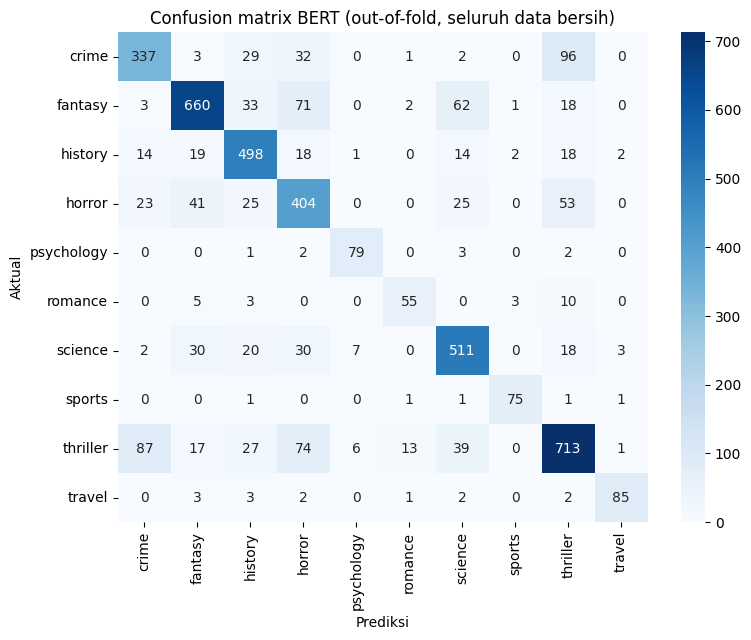

In [ ]:
if len(cv_results) == N_FOLDS:
    bert_oof = np.zeros(len(df), dtype=int)
    for r in cv_results:
        bert_oof[r["idx"]] = r["y_pred"]
    assert all((r["y_true"] == y_all[r["idx"]]).all() for r in cv_results), "indeks fold tidak selaras"
    print("BERT OOF accuracy:", round((bert_oof == y_all).mean() * 100, 2), "| F1-macro:", round(f1_score(y_all, bert_oof, average='macro'), 3))

    # McNemar pada SEMUA prediksi out-of-fold
    rows = []
    for name in oof_pred:
        n01, n10, p = mcnemar_exact(y_all, bert_oof, oof_pred[name])
        rows.append({"BERT vs": name, "BERT benar / lawan salah": n01, "kebalikannya": n10,
                     "p-value": f"{p:.3g}", "signifikan (p<0.05)": "ya" if p < 0.05 else "tidak"})
    print("\nMcNemar out-of-fold (n = seluruh data bersih):")
    display(pd.DataFrame(rows))

    # F1 per genre (out-of-fold)
    idx_lbl = np.arange(num_labels)
    per_genre = pd.DataFrame({"genre": label_names, "support": np.bincount(y_all, minlength=num_labels)})
    per_genre["BERT"] = f1_score(y_all, bert_oof, average=None, labels=idx_lbl)
    for name in oof_pred:
        per_genre[name.strip()] = f1_score(y_all, oof_pred[name], average=None, labels=idx_lbl)
    per_genre = per_genre.round(3)
    print("\nF1 per genre (out-of-fold):")
    display(per_genre)

    # pola kesalahan BERT
    cm = confusion_matrix(y_all, bert_oof, labels=idx_lbl)
    pairs = [(label_names[i], label_names[j], int(cm[i, j])) for i in range(num_labels) for j in range(num_labels) if i != j]
    top_err = pd.DataFrame(sorted(pairs, key=lambda x: -x[2])[:10], columns=["aktual", "diprediksi", "jumlah"])
    print("\n10 kesalahan BERT terbanyak (aktual -> diprediksi):")
    display(top_err)

    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
    plt.title('Confusion matrix BERT (out-of-fold, seluruh data bersih)'); plt.xlabel('Prediksi'); plt.ylabel('Aktual')
    plt.tight_layout(); plt.show()
else:
    print(f"BERT CV belum lengkap ({len(cv_results)}/{N_FOLDS} fold). Jalankan RUN_BERT_CV=True.")

## Cek kewarasan dan penyimpanan hasil

In [ ]:
print("Duplikat summary di data bersih     :", int(df.duplicated(subset='summary', keep=False).sum()), "(harus 0)")
print("Summary test identik dengan train   :", int(test_df['summary'].isin(set(train_df['summary'])).sum()), "(harus 0)")
print("Irisan indeks train/val/test        :", len(set(train_df.index) & set(test_df.index)) + len(set(train_df.index) & set(val_df.index)) + len(set(val_df.index) & set(test_df.index)), "(harus 0)")

os.makedirs("hasil", exist_ok=True)
final_comparison.to_csv("hasil/perbandingan_split_tetap.csv", index=False)
cv_summary.to_csv("hasil/ringkasan_cv.csv")
cv_all.to_csv("hasil/cv_per_fold.csv", index=False)
cmp.to_csv("hasil/distribusi_genre_asli_vs_bersih.csv")
if 'per_genre' in globals():
    per_genre.to_csv("hasil/f1_per_genre_oof.csv", index=False)
pd.DataFrame([{"data_asli": n_raw, "baris_terlibat_duplikat": dup_rows, "sinopsis_label_konflik": n_conflict,
               "data_bersih": len(df)}]).to_csv("hasil/statistik_data.csv", index=False)
print("Tersimpan di folder hasil/:", os.listdir("hasil"))
try:
    from google.colab import files
    shutil.make_archive("hasil_eksperimen", "zip", "hasil")
    files.download("hasil_eksperimen.zip")
except Exception as e:
    print("Unduh manual folder hasil/ (bukan di Colab):", type(e).__name__)

Duplikat summary di data bersih     : 0 (harus 0)
Summary test identik dengan train   : 0 (harus 0)
Irisan indeks train/val/test        : 0 (harus 0)
Tersimpan di folder hasil/: ['f1_per_genre_oof.csv', 'distribusi_genre_asli_vs_bersih.csv', 'cv_per_fold.csv', 'ringkasan_cv.csv', 'perbandingan_split_tetap.csv', 'statistik_data.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### TAMBAHAN VISUALISASI

Rata-rata token per dokumen tiap tahap: {'1. Token mentah': np.float64(368.5), '2-3. Lowercase+cleaning+tokenisasi': np.float64(375.6), '4. Stopword+token pendek dibuang': np.float64(184.5)}
Kosakata unik sebelum stemming : 53557
Kosakata unik sesudah stemming : 37798  (-29.4%)


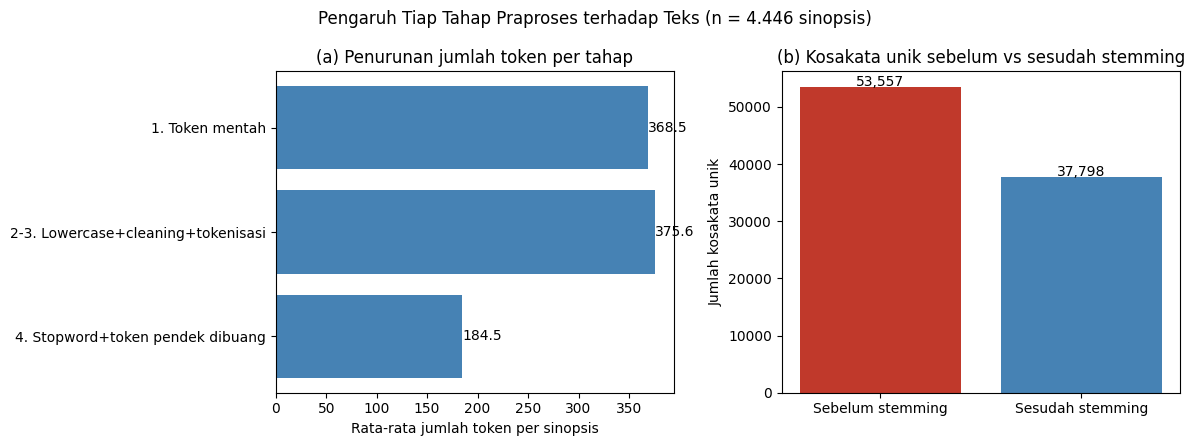

In [ ]:
# ==== Visualisasi kuantitatif tiap tahap praproses (seluruh dataset) ====

def hitung_tahap(text):
    asli = str(text).split()                                              # tahap 1: split mentah
    low = str(text).lower()
    cleaned = re.sub(r'[^a-z\s]', ' ', low).split()                       # tahap 2+3: lowercase+cleaning+tokenisasi
    filtered = [t for t in cleaned if t not in stop_words and len(t) > 2] # tahap 4: stopword+token pendek
    stemmed = [stemmer.stem(t) for t in filtered]                        # tahap 5: stemming (jumlah token sama)
    return len(asli), len(cleaned), len(filtered), filtered, stemmed

hasil_tahap = df['summary'].apply(hitung_tahap)
rata2 = {
    "1. Token mentah": hasil_tahap.apply(lambda x: x[0]).mean(),
    "2-3. Lowercase+cleaning+tokenisasi": hasil_tahap.apply(lambda x: x[1]).mean(),
    "4. Stopword+token pendek dibuang": hasil_tahap.apply(lambda x: x[2]).mean(),
}

vocab_sebelum_stem = len(set(t for row in hasil_tahap for t in row[3]))
vocab_sesudah_stem  = len(set(t for row in hasil_tahap for t in row[4]))

print("Rata-rata token per dokumen tiap tahap:", {k: round(v,1) for k,v in rata2.items()})
print(f"Kosakata unik sebelum stemming : {vocab_sebelum_stem}")
print(f"Kosakata unik sesudah stemming : {vocab_sesudah_stem}  (-{(1-vocab_sesudah_stem/vocab_sebelum_stem)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) funnel chart: rata-rata token per dokumen per tahap
tahap_nama = list(rata2.keys())
tahap_nilai = list(rata2.values())
axes[0].barh(tahap_nama, tahap_nilai, color="steelblue")
for i, v in enumerate(tahap_nilai):
    axes[0].text(v + 0.5, i, f"{v:.1f}", va="center")
axes[0].invert_yaxis()
axes[0].set_xlabel("Rata-rata jumlah token per sinopsis")
axes[0].set_title("(a) Penurunan jumlah token per tahap")

# (b) kosakata unik sebelum vs sesudah stemming
axes[1].bar(["Sebelum stemming", "Sesudah stemming"],
            [vocab_sebelum_stem, vocab_sesudah_stem], color=["#c0392b", "steelblue"])
for i, v in enumerate([vocab_sebelum_stem, vocab_sesudah_stem]):
    axes[1].text(i, v + 50, f"{v:,}", ha="center")
axes[1].set_ylabel("Jumlah kosakata unik")
axes[1].set_title("(b) Kosakata unik sebelum vs sesudah stemming")

plt.suptitle("Pengaruh Tiap Tahap Praproses terhadap Teks (n = 4.446 sinopsis)")
plt.tight_layout()
os.makedirs("hasil", exist_ok=True)
plt.savefig("hasil/praproses_tahap.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# --- siapkan "combined" = ringkasan k saat ini, siap digabung lintas notebook ---
combined = cv_summary.reset_index().rename(columns={"model": "model"})
combined["k"] = N_FOLDS
combined = combined[["model", "k", "acc_mean", "acc_std", "f1_mean", "f1_std",
                      "kappa_mean", "kappa_std", "waktu_per_fold_detik", "n_fold"]]

os.makedirs("hasil", exist_ok=True)
combined.to_csv(f"hasil/ringkasan_cv_k{N_FOLDS}_lengkap.csv", index=False)
print(f"Tersimpan: hasil/ringkasan_cv_k{N_FOLDS}_lengkap.csv  (k={N_FOLDS})")
display(combined)

Tersimpan: hasil/ringkasan_cv_k5_lengkap.csv  (k=5)


,model,k,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,kappa_std,waktu_per_fold_detik,n_fold
0,BERT (weighted loss),5,76.855,1.221,0.798,0.011,0.727,0.015,814.178,5
1,"SVM (vocab penuh, 1-2gram)",5,75.146,1.805,0.752,0.020,0.707,0.021,2.063,5
2,"LR (vocab penuh, 1-2gram)",5,75.371,1.527,0.749,0.023,0.708,0.018,14.515,5
3,A5: RF vocab penuh (class_weight),5,63.338,1.156,0.627,0.011,0.568,0.013,28.792,5
4,"LR (top500, class_weight)",5,61.066,2.515,0.578,0.016,0.548,0.028,0.972,5
5,"RF (top500, class_weight)",5,57.265,1.989,0.540,0.016,0.502,0.022,9.656,5
6,"RF (top500, tanpa balancing)",5,58.367,2.145,0.428,0.031,0.496,0.027,11.398,5
7,A4: RF vocab penuh (tanpa balancing),5,60.346,1.946,0.408,0.020,0.517,0.024,33.160,5


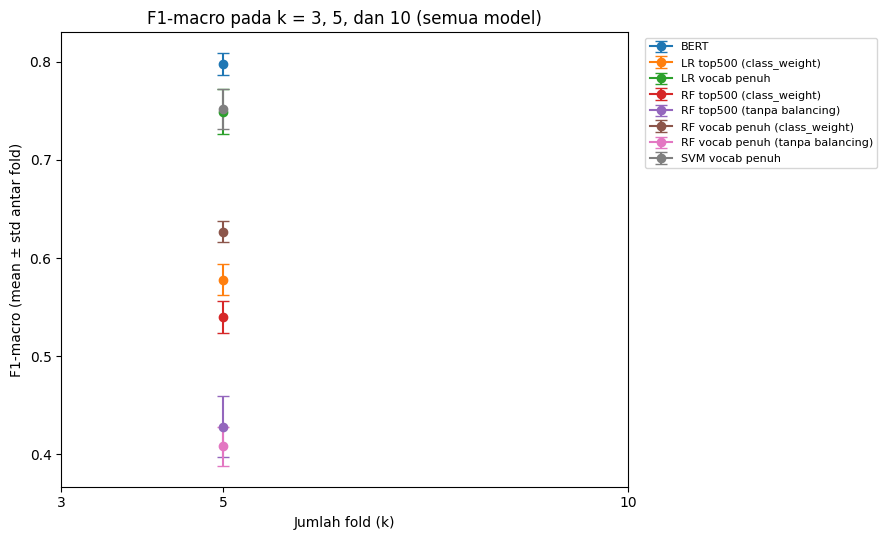

In [ ]:
# samain nama model antar notebook biar nyambung
NAMA_SAMA = {
    "RF  (top500, tanpa balancing)": "RF top500 (tanpa balancing)",
    "RF  (top500, class_weight)": "RF top500 (class_weight)",
    "LR  (top500, class_weight)": "LR top500 (class_weight)",
    "LR  (vocab penuh, 1-2gram)": "LR vocab penuh",
    "SVM (vocab penuh, 1-2gram)": "SVM vocab penuh",
    "A4: RF vocab penuh (tanpa balancing)": "RF vocab penuh (tanpa balancing)",
    "A5: RF vocab penuh (class_weight)": "RF vocab penuh (class_weight)",
    "BERT (weighted loss)": "BERT",
    "BERT": "BERT",
}


# --- (a) errorbar F1-macro vs k, semua model ---
plt.figure(figsize=(9, 5.5))
for name, grp in semua_k.groupby("model"):
    grp = grp.sort_values("k")
    plt.errorbar(grp["k"], grp["f1_mean"], yerr=grp["f1_std"], marker="o", capsize=4, label=name)
plt.xlabel("Jumlah fold (k)"); plt.ylabel("F1-macro (mean ± std antar fold)")
plt.title("F1-macro pada k = 3, 5, dan 10 (semua model)")
plt.xticks([3, 5, 10])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("hasil/f1_vs_k_lengkap.png", dpi=150, bbox_inches="tight"); plt.show()



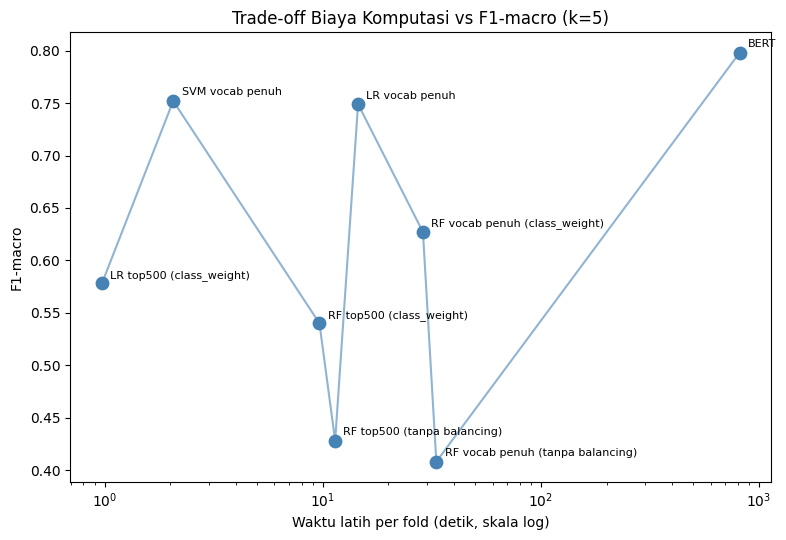

In [ ]:
# --- (b) scatter + garis trade-off: waktu latih vs F1-macro (snapshot k=5) ---
snap = semua_k[semua_k["k"] == 5].copy()
snap = snap.sort_values("waktu_per_fold_detik")  # urutkan dulu biar garis nyambung rapi

fig, ax = plt.subplots(figsize=(8, 5.5))

# garis penghubung
ax.plot(snap["waktu_per_fold_detik"], snap["f1_mean"],
        linestyle="-", linewidth=1.5, color="steelblue", alpha=0.6, zorder=2)

# titik-titik (tetap dipertahankan)
ax.scatter(snap["waktu_per_fold_detik"], snap["f1_mean"],
           s=80, color="steelblue", zorder=3)

for _, r in snap.iterrows():
    ax.annotate(r["model"], (r["waktu_per_fold_detik"], r["f1_mean"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)

ax.set_xscale("log")
ax.set_xlabel("Waktu latih per fold (detik, skala log)")
ax.set_ylabel("F1-macro")
ax.set_title("Trade-off Biaya Komputasi vs F1-macro (k=5)")

plt.tight_layout()
plt.savefig("hasil/tradeoff_waktu_f1.png", dpi=150, bbox_inches="tight")
plt.show()

,"RF (top500, tanpa balancing)","RF (top500, class_weight)","LR (top500, class_weight)","LR (vocab penuh, 1-2gram)","SVM (vocab penuh, 1-2gram)",A4: RF vocab penuh (tanpa balancing),A5: RF vocab penuh (class_weight),BERT
crime,0.546,0.577,0.622,0.736,0.725,0.564,0.623,0.698
fantasy,0.658,0.628,0.662,0.794,0.791,0.672,0.675,0.811
history,0.633,0.611,0.651,0.767,0.771,0.630,0.666,0.812
horror,0.466,0.505,0.578,0.696,0.686,0.470,0.543,0.671
psychology,0.109,0.400,0.558,0.835,0.834,0.067,0.805,0.878
romance,0.051,0.420,0.364,0.514,0.551,0.000,0.186,0.738
science,0.660,0.649,0.661,0.778,0.781,0.700,0.707,0.798
sports,0.215,0.595,0.516,0.832,0.859,0.295,0.826,0.932
thriller,0.580,0.520,0.565,0.734,0.729,0.614,0.552,0.747
travel,0.379,0.490,0.607,0.816,0.806,0.097,0.703,0.895


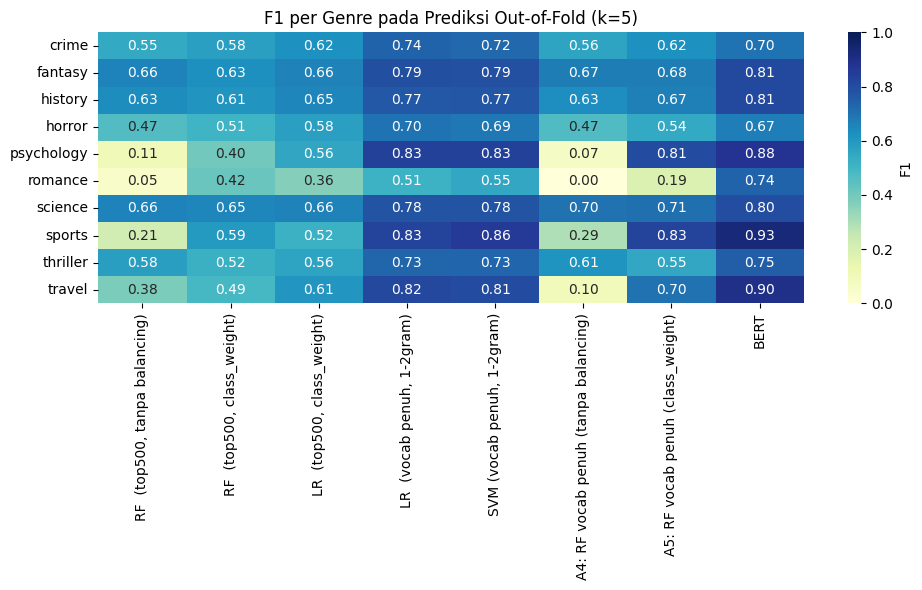

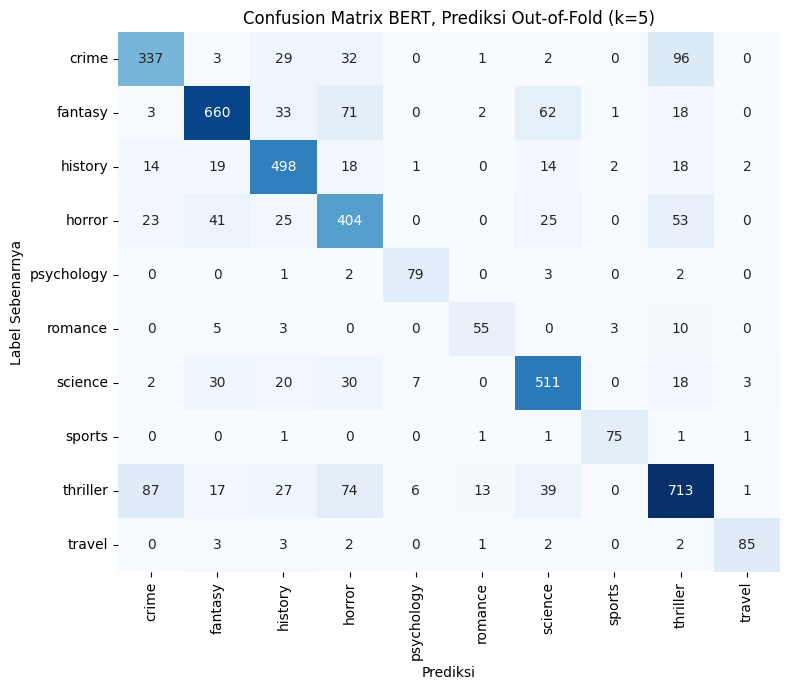

In [ ]:
import seaborn as sns
from sklearn.metrics import f1_score, confusion_matrix

oof_semua = dict(oof_pred)          # sudah termasuk A4/A5, tidak perlu rf_full
if bert_oof is not None:
    oof_semua["BERT"] = bert_oof

genre_list = label_names  # dari LabelEncoder, urutan sesuai y_all
f1_per_genre = {}
for name, pred in oof_semua.items():
    f1_per_genre[name] = f1_score(y_all, pred, average=None, labels=range(len(genre_list)))
f1_df = pd.DataFrame(f1_per_genre, index=genre_list).round(3)
display(f1_df)

# --- (a) heatmap F1 per genre x model ---
plt.figure(figsize=(10, 6))
sns.heatmap(f1_df, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, cbar_kws={"label": "F1"})
plt.title(f"F1 per Genre pada Prediksi Out-of-Fold (k={N_FOLDS})")
plt.tight_layout(); plt.savefig("hasil/heatmap_f1_genre.png", dpi=150, bbox_inches="tight"); plt.show()

# --- (b) confusion matrix BERT out-of-fold ---
cm = confusion_matrix(y_all, oof_semua["BERT"], labels=range(len(genre_list)))
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=genre_list, yticklabels=genre_list, cbar=False)
plt.xlabel("Prediksi"); plt.ylabel("Label Sebenarnya")
plt.title(f"Confusion Matrix BERT, Prediksi Out-of-Fold (k={N_FOLDS})")
plt.tight_layout(); plt.savefig("hasil/cm_bert_oof.png", dpi=150, bbox_inches="tight"); plt.show()

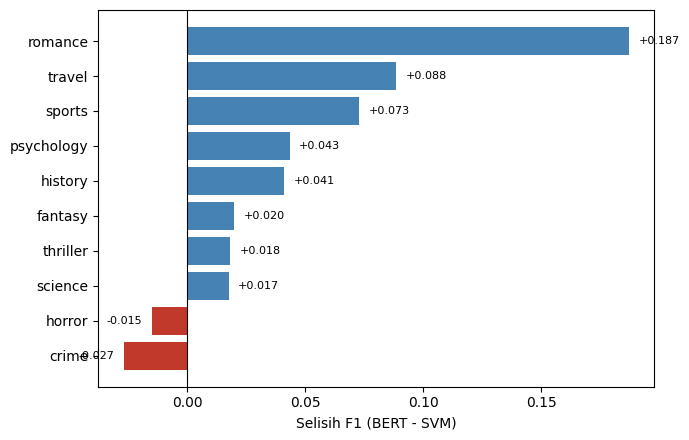

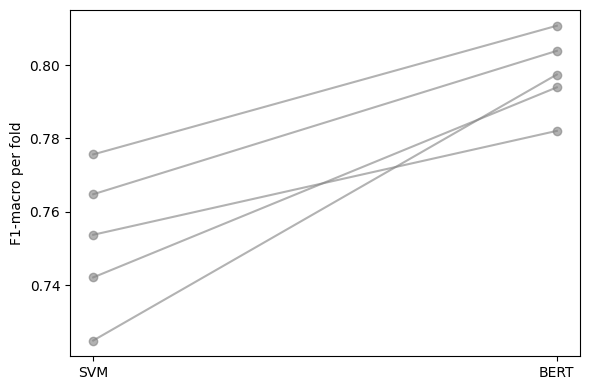

BERT > SVM pada 5 dari 5 fold


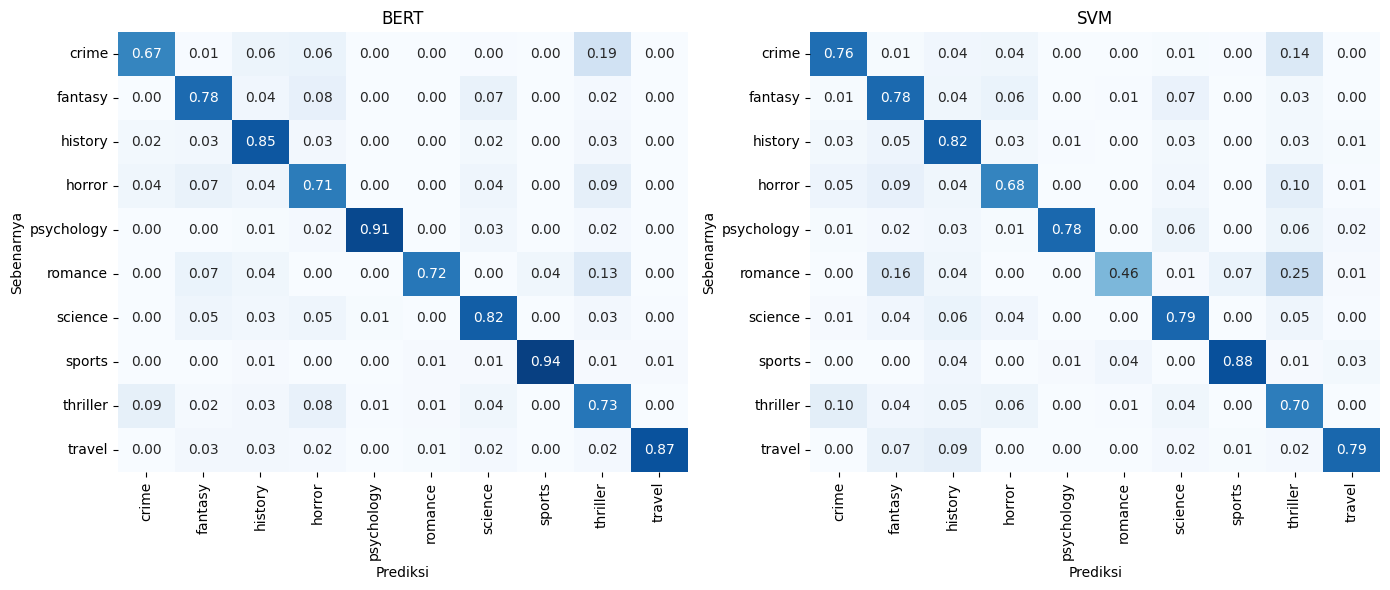

In [ ]:
import numpy as np, os
os.makedirs("hasil/gambar", exist_ok=True)
SV, BE = "SVM (vocab penuh, 1-2gram)", "BERT (weighted loss)"

# 1) Selisih F1 per genre (BERT - SVM)
fb = f1_score(y_all, oof_semua["BERT"], average=None)
fs = f1_score(y_all, oof_semua[SV], average=None)
d = fb - fs; o = np.argsort(d)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(np.array(label_names)[o], d[o], color=["#c0392b" if x < 0 else "steelblue" for x in d[o]])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Selisih F1 (BERT - SVM)")
for i, x in enumerate(d[o]):
    ax.text(x + (0.004 if x >= 0 else -0.004), i, f"{x:+.3f}", va="center",
            ha="left" if x >= 0 else "right", fontsize=8)
plt.tight_layout(); plt.savefig("hasil/gambar/selisih_f1_genre.png", dpi=300, bbox_inches="tight"); plt.show()

# 2) Per-fold: F1-macro BERT vs SVM (garis berpasangan)
pf = cv_all[cv_all["model"].isin([BE, SV])].pivot(index="fold", columns="model", values="f1_macro")
fig, ax = plt.subplots(figsize=(6, 4))
for f, r in pf.iterrows(): ax.plot(["SVM", "BERT"], [r[SV], r[BE]], "o-", color="gray", alpha=.6)
ax.set_ylabel("F1-macro per fold"); plt.tight_layout()
plt.savefig("hasil/gambar/perfold_bert_vs_svm.png", dpi=300, bbox_inches="tight"); plt.show()
print(f"BERT > SVM pada {(pf[BE] > pf[SV]).sum()} dari {len(pf)} fold")

# 3) Confusion matrix ternormalisasi (baris = 100%)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (nm, key) in zip(axes, [("BERT", "BERT"), ("SVM", SV)]):
    cm = confusion_matrix(y_all, oof_semua[key], labels=range(len(label_names)))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=label_names, yticklabels=label_names, cbar=False, ax=ax)
    ax.set_title(nm); ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.tight_layout(); plt.savefig("hasil/gambar/cm_normalisasi.png", dpi=300, bbox_inches="tight"); plt.show()

TAMBAHAN A1 dan B2

In [ ]:
# ============================================================
# Evaluasi A1 dan B2 pada k=3, 5, dan 10 — fold identik dengan
# model lain agar perbandingan di Tabel 7 adil (fair)
# ============================================================
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

SEED = 42
N_BALANCE = 100  # sesuai replikasi metode [4]: 100 sampel/genre dengan penggantian


def run_a1_fold(train_df, test_df):
    """A1: RF 500 fitur. Vocab 500 kata ditentukan dari SELURUH train fold
    (sebelum balancing), baru resampling 100/kelas diterapkan -- sesuai urutan
    operasi metode [4] yang direplikasi."""
    tfidf = TfidfVectorizer(max_features=500)
    tfidf.fit(train_df['clean_summary'])  # vocab dari train fold utuh

    rng = np.random.RandomState(SEED)
    balanced_idx = []
    for lbl in train_df['label'].unique():
        idx_lbl = train_df.index[train_df['label'] == lbl].tolist()
        sampled = rng.choice(idx_lbl, size=N_BALANCE, replace=True)
        balanced_idx.extend(sampled)
    train_bal = train_df.loc[balanced_idx]

    X_train = tfidf.transform(train_bal['clean_summary'])
    X_test = tfidf.transform(test_df['clean_summary'])

    t0 = time.time()
    clf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    clf.fit(X_train, train_bal['label'].values)
    elapsed = time.time() - t0

    return clf.predict(X_test), elapsed


def run_b2_fold(train_df, test_df):
    """B2: SVM linear 500 fitur, class_weight='balanced', TANPA resampling apapun."""
    tfidf = TfidfVectorizer(max_features=500)
    X_train = tfidf.fit_transform(train_df['clean_summary'])
    X_test = tfidf.transform(test_df['clean_summary'])

    t0 = time.time()
    clf = LinearSVC(class_weight='balanced', random_state=SEED, max_iter=5000)
    clf.fit(X_train, train_df['label'].values)
    elapsed = time.time() - t0

    return clf.predict(X_test), elapsed


results_a1_b2 = []

for k in [3, 5, 10]:
    print(f"\n=== k = {k} ===")
    # Fold IDENTIK dengan model lain: sama seed, sama cara split
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    folds = list(skf.split(df.index.values, df['label'].values))

    a1_acc, a1_f1, a1_kap, a1_time = [], [], [], []
    b2_acc, b2_f1, b2_kap, b2_time = [], [], [], []
    a1_oof_pred = np.full(len(df), -1)
    b2_oof_pred = np.full(len(df), -1)

    for fold_i, (train_idx, test_idx) in enumerate(folds, start=1):
        train_fold = df.iloc[train_idx]
        test_fold = df.iloc[test_idx]
        y_true = test_fold['label'].values

        y_pred_a1, t_a1 = run_a1_fold(train_fold, test_fold)
        a1_acc.append(accuracy_score(y_true, y_pred_a1) * 100)
        a1_f1.append(f1_score(y_true, y_pred_a1, average='macro'))
        a1_kap.append(cohen_kappa_score(y_true, y_pred_a1))
        a1_time.append(t_a1)
        a1_oof_pred[test_idx] = y_pred_a1

        y_pred_b2, t_b2 = run_b2_fold(train_fold, test_fold)
        b2_acc.append(accuracy_score(y_true, y_pred_b2) * 100)
        b2_f1.append(f1_score(y_true, y_pred_b2, average='macro'))
        b2_kap.append(cohen_kappa_score(y_true, y_pred_b2))
        b2_time.append(t_b2)
        b2_oof_pred[test_idx] = y_pred_b2

        print(f"  Fold {fold_i}/{k} | A1 acc={a1_acc[-1]:.2f}% f1={a1_f1[-1]:.3f} "
              f"| B2 acc={b2_acc[-1]:.2f}% f1={b2_f1[-1]:.3f}")

    results_a1_b2.append({
        "model": "A1: RF 500 fitur, penyeimbangan manual", "k": k,
        "acc_mean": np.mean(a1_acc), "acc_std": np.std(a1_acc),
        "f1_mean": np.mean(a1_f1), "f1_std": np.std(a1_f1),
        "kappa_mean": np.mean(a1_kap), "kappa_std": np.std(a1_kap),
        "waktu_per_fold_detik": np.mean(a1_time),
    })
    results_a1_b2.append({
        "model": "B2: SVM linear, 500 fitur", "k": k,
        "acc_mean": np.mean(b2_acc), "acc_std": np.std(b2_acc),
        "f1_mean": np.mean(b2_f1), "f1_std": np.std(b2_f1),
        "kappa_mean": np.mean(b2_kap), "kappa_std": np.std(b2_kap),
        "waktu_per_fold_detik": np.mean(b2_time),
    })

    # simpan prediksi out-of-fold tiap k, kalau nanti mau analisis per genre juga
    globals()[f"a1_oof_pred_k{k}"] = a1_oof_pred
    globals()[f"b2_oof_pred_k{k}"] = b2_oof_pred

df_a1_b2_cv = pd.DataFrame(results_a1_b2)
print("\n=== Ringkasan A1 & B2 pada k=3, 5, 10 ===")
display(df_a1_b2_cv.round(3))

import os
os.makedirs("hasil", exist_ok=True)
df_a1_b2_cv.to_csv("hasil/a1_b2_cv_k3_5_10.csv", index=False)
print("\nTersimpan: hasil/a1_b2_cv_k3_5_10.csv")


=== k = 3 ===
  Fold 1/3 | A1 acc=45.21% f1=0.420 | B2 acc=56.55% f1=0.521
  Fold 2/3 | A1 acc=48.25% f1=0.437 | B2 acc=58.70% f1=0.542
  Fold 3/3 | A1 acc=43.99% f1=0.411 | B2 acc=57.76% f1=0.535

=== k = 5 ===
  Fold 1/5 | A1 acc=46.29% f1=0.441 | B2 acc=58.99% f1=0.536
  Fold 2/5 | A1 acc=47.81% f1=0.442 | B2 acc=61.53% f1=0.555
  Fold 3/5 | A1 acc=45.11% f1=0.424 | B2 acc=59.84% f1=0.585
  Fold 4/5 | A1 acc=46.01% f1=0.429 | B2 acc=59.84% f1=0.553
  Fold 5/5 | A1 acc=43.53% f1=0.403 | B2 acc=57.26% f1=0.557

=== k = 10 ===
  Fold 1/10 | A1 acc=49.89% f1=0.449 | B2 acc=62.25% f1=0.573
  Fold 2/10 | A1 acc=42.92% f1=0.400 | B2 acc=53.93% f1=0.504
  Fold 3/10 | A1 acc=45.39% f1=0.409 | B2 acc=58.43% f1=0.533
  Fold 4/10 | A1 acc=47.19% f1=0.440 | B2 acc=63.60% f1=0.545
  Fold 5/10 | A1 acc=42.25% f1=0.387 | B2 acc=57.98% f1=0.553
  Fold 6/10 | A1 acc=45.39% f1=0.434 | B2 acc=62.92% f1=0.625
  Fold 7/10 | A1 acc=44.59% f1=0.404 | B2 acc=59.23% f1=0.542
  Fold 8/10 | A1 acc=49.10% f1=0

,model,k,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,kappa_std,waktu_per_fold_detik
0,"A1: RF 500 fitur, penyeimbangan manual",3,45.816,1.788,0.423,0.011,0.387,0.019,1.953
1,"B2: SVM linear, 500 fitur",3,57.670,0.884,0.533,0.009,0.505,0.009,0.132
2,"A1: RF 500 fitur, penyeimbangan manual",5,45.749,1.409,0.428,0.014,0.386,0.013,1.966
3,"B2: SVM linear, 500 fitur",5,59.492,1.390,0.557,0.016,0.526,0.015,0.154
4,"A1: RF 500 fitur, penyeimbangan manual",10,45.479,2.410,0.419,0.020,0.384,0.024,1.963
5,"B2: SVM linear, 500 fitur",10,59.694,2.970,0.562,0.032,0.529,0.034,0.172



Tersimpan: hasil/a1_b2_cv_k3_5_10.csv


In [ ]:
# ============================================================
# C2: BERT tanpa class-weighted loss -- TANPA FOLD
# (pembagian tetap 70/15/15, sama seperti model C asli di Tabel 6)
# ============================================================
import os, gc, shutil, time
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MAX_LENGTH_ABLASI = 256   # SAMA dengan BERT utama -- biar variabel yang beda cuma bobot kelas
tokenizer_ablasi = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_ablasi(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_ablasi(b['summary'], truncation=True,
                                            padding='max_length', max_length=MAX_LENGTH_ABLASI),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_ablasi(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=16, per_device_eval_batch_size=32,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_ablasi(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_unweighted_single(train_part, val_part, test_part):
    tr, va, te = to_ds_ablasi(train_part), to_ds_ablasi(val_part), to_ds_ablasi(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = "./bert_ablasi_single"

    trainer = Trainer(  # Trainer BIASA, bukan WeightedTrainer -- tanpa bobot kelas
        model=model, args=make_args_ablasi(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_ablasi,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}


# --- Jalankan 1x pada pembagian tetap (train_df, val_df, test_df sudah ada) ---
print("Menjalankan BERT TANPA class-weighted loss pada pembagian tetap 70/15/15...")
r_ablasi = run_bert_unweighted_single(train_df, val_df, test_df)

acc_ablasi = accuracy_score(r_ablasi["y_true"], r_ablasi["y_pred"]) * 100
f1_ablasi = f1_score(r_ablasi["y_true"], r_ablasi["y_pred"], average="macro")
kap_ablasi = cohen_kappa_score(r_ablasi["y_true"], r_ablasi["y_pred"])

# ============================================================
# RINGKASAN HASIL
# ============================================================
print("\n" + "="*60)
print("RINGKASAN: BERT tanpa class-weighted loss (pembagian tetap)")
print("="*60)
print(f"Akurasi   : {acc_ablasi:.2f}%")
print(f"F1-macro  : {f1_ablasi:.3f}")
print(f"Kappa     : {kap_ablasi:.3f}")
print(f"Waktu latih: {r_ablasi['time_sec']:.1f} detik ({r_ablasi['time_sec']/60:.1f} menit)")

# --- Perbandingan langsung dengan BERT berbobot (model C, Tabel 6) ---
BASELINE_C_ACC = 80.21
BASELINE_C_F1 = 0.839
BASELINE_C_KAPPA = 0.767
BASELINE_C_TIME = 801.6

print(f"\n--- Perbandingan dengan BERT berbobot kelas (model C, Tabel 6) ---")
print(f"{'Metrik':<15}{'Berbobot (C)':<15}{'Tanpa bobot':<15}{'Selisih':<12}")
print(f"{'Akurasi (%)':<15}{BASELINE_C_ACC:<15.2f}{acc_ablasi:<15.2f}{acc_ablasi-BASELINE_C_ACC:+.2f}")
print(f"{'F1-macro':<15}{BASELINE_C_F1:<15.3f}{f1_ablasi:<15.3f}{f1_ablasi-BASELINE_C_F1:+.3f}")
print(f"{'Kappa':<15}{BASELINE_C_KAPPA:<15.3f}{kap_ablasi:<15.3f}{kap_ablasi-BASELINE_C_KAPPA:+.3f}")
print(f"{'Waktu (detik)':<15}{BASELINE_C_TIME:<15.1f}{r_ablasi['time_sec']:<15.1f}{r_ablasi['time_sec']-BASELINE_C_TIME:+.1f}")

# --- F1 per genre ---
f1_per_genre_ablasi = f1_score(r_ablasi["y_true"], r_ablasi["y_pred"], average=None, labels=range(num_labels))

print(f"\n--- F1 per genre (tanpa bobot, pembagian tetap) ---")
df_genre_ablasi = pd.DataFrame({
    "genre": label_names,
    "f1_tanpa_bobot": f1_per_genre_ablasi.round(3)
}).sort_values("f1_tanpa_bobot", ascending=False)
display(df_genre_ablasi)

os.makedirs("hasil", exist_ok=True)
df_genre_ablasi.to_csv("hasil/ablasi_single_per_genre.csv", index=False)

pd.DataFrame([{
    "akurasi": acc_ablasi, "f1_macro": f1_ablasi, "kappa": kap_ablasi,
    "waktu_detik": r_ablasi["time_sec"]
}]).to_csv("hasil/ablasi_single_ringkasan.csv", index=False)

print("\nTersimpan: hasil/ablasi_single_ringkasan.csv dan hasil/ablasi_single_per_genre.csv")

Menjalankan BERT TANPA class-weighted loss pada pembagian tetap 70/15/15...


Map:   0%|          | 0/3112 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


RINGKASAN: BERT tanpa class-weighted loss (pembagian tetap)
Akurasi   : 79.61%
F1-macro  : 0.834
Kappa     : 0.760
Waktu latih: 1089.4 detik (18.2 menit)

--- Perbandingan dengan BERT berbobot kelas (model C, Tabel 6) ---
Metrik         Berbobot (C)   Tanpa bobot    Selisih     
Akurasi (%)    80.21          79.61          -0.60
F1-macro       0.839          0.834          -0.005
Kappa          0.767          0.760          -0.007
Waktu (detik)  801.6          1089.4         +287.8

--- F1 per genre (tanpa bobot, pembagian tetap) ---


,genre,f1_tanpa_bobot
7,sports,1.000
5,romance,0.917
4,psychology,0.897
9,travel,0.857
6,science,0.845
1,fantasy,0.840
2,history,0.802
8,thriller,0.792
0,crime,0.715
3,horror,0.678



Tersimpan: hasil/ablasi_single_ringkasan.csv dan hasil/ablasi_single_per_genre.csv


In [ ]:
# ============================================================
# C2: BERT TANPA class-weighted loss (cross-entropy biasa)
# Dijalankan pada k yang sama (gunakan salah satu, misal k=5,
# atau ulangi untuk k=3,5,10 kalau waktu memungkinkan)
# ============================================================

def run_bert_unweighted_fold(train_part, val_part, test_part, tag):
    """Sama persis dengan run_bert() yang sudah ada, TAPI tanpa
    class_weight pada loss function -- pakai CrossEntropyLoss standar."""
    tr, va, te = to_ds(train_part), to_ds(val_part), to_ds(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = f"./bert_unweighted_{tag}"

    # Trainer BIASA (bukan WeightedTrainer) -- loss default tanpa bobot kelas
    trainer = Trainer(
        model=model,
        args=make_training_args(out_dir, len(tr)),
        train_dataset=tr,
        eval_dataset=va,
        compute_metrics=bert_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0

    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)

    del model, trainer
    gc.collect(); torch.cuda.empty_cache(); shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}


# Jalankan pada k=5 saja dulu (cukup untuk ablasi, hemat waktu)
K_ABLASI = 5
skf = StratifiedKFold(n_splits=K_ABLASI, shuffle=True, random_state=SEED)
folds_ablasi = list(skf.split(df.index.values, df['label'].values))

bert_unweighted_results = []
for fold, (tr_idx, te_idx) in enumerate(folds_ablasi, start=1):
    tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
    tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                         stratify=tv_part['label'], random_state=SEED)
    r = run_bert_unweighted_fold(tr_part, va_part, te_part, f"ablasi{fold}")
    acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
    f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
    print(f"Fold {fold}/{K_ABLASI} | acc={acc:.2f}% f1={f1m:.3f}")
    bert_unweighted_results.append({"fold": fold, "y_true": r["y_true"],
                                     "y_pred": r["y_pred"], "time_sec": r["time_sec"]})

# F1 per genre untuk perbandingan langsung dengan BERT berbobot (Tabel 8)
y_true_all = np.concatenate([r["y_true"] for r in bert_unweighted_results])
y_pred_all = np.concatenate([r["y_pred"] for r in bert_unweighted_results])
f1_per_genre_unweighted = f1_score(y_true_all, y_pred_all, average=None,
                                     labels=range(num_labels))
print("\nF1 per genre, BERT TANPA class weighting:")
for genre, f1 in zip(label_names, f1_per_genre_unweighted):
    print(f"  {genre}: {f1:.3f}")

Map:   0%|          | 0/3022 [00:00<?, ? examples/s]

Map:   0%|          | 0/534 [00:00<?, ? examples/s]

Map:   0%|          | 0/890 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 5/5 | acc=76.04% f1=0.776

F1 per genre, BERT TANPA class weighting:
  crime: 0.721
  fantasy: 0.806
  history: 0.812
  horror: 0.671
  psychology: 0.860
  romance: 0.696
  science: 0.792
  sports: 0.916
  thriller: 0.743
  travel: 0.857


In [ ]:
import os

os.makedirs("hasil", exist_ok=True)

In [ ]:
# ============================================================
# C3: BERT max_length=512 -- uji coba cepat TANPA fold
# (pembagian tetap 70/15/15, sama seperti model C asli di Tabel 6)
# ============================================================
from sklearn.utils.class_weight import compute_class_weight

MAX_LENGTH_512 = 512
BATCH_SIZE_512 = 16   # diturunkan dari 16 -> 8, token lebih panjang butuh memori lebih besar

tokenizer_512 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_512(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_512(b['summary'], truncation=True,
                                         padding='max_length', max_length=MAX_LENGTH_512),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_512(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_512, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_512(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_512_single(train_part, val_part, test_part):
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds_512(train_part), to_ds_512(val_part), to_ds_512(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = "./bert_512_single"

    class WeightedTrainer512(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = torch.nn.CrossEntropyLoss(weight=w)(outputs.logits, labels)
            return (loss, outputs) if return_outputs else loss

    trainer = WeightedTrainer512(
        model=model, args=make_args_512(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_512,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}


# --- Jalankan 1x pada pembagian tetap (train_df, val_df, test_df sudah ada) ---
print("Menjalankan BERT max_length=512 pada pembagian tetap 70/15/15...")
r_512 = run_bert_512_single(train_df, val_df, test_df)

acc_512 = accuracy_score(r_512["y_true"], r_512["y_pred"]) * 100
f1_512 = f1_score(r_512["y_true"], r_512["y_pred"], average="macro")
kap_512 = cohen_kappa_score(r_512["y_true"], r_512["y_pred"])

print(f"\n=== Hasil BERT max_length=512 (pembagian tetap) ===")
print(f"Akurasi   : {acc_512:.2f}%")
print(f"F1-macro  : {f1_512:.3f}")
print(f"Kappa     : {kap_512:.3f}")
print(f"Waktu latih: {r_512['time_sec']:.1f} detik ({r_512['time_sec']/60:.1f} menit)")
print(f"\nBandingkan dengan BERT max_length=256 (Tabel 6, model C):")
print(f"  Akurasi 80,21% | F1-macro 0,839 | Kappa 0,767 | Waktu 801,6 detik")

# F1 per genre, untuk lihat apakah genre dengan sinopsis panjang (yang tadinya kepotong) membaik
f1_per_genre_512 = f1_score(r_512["y_true"], r_512["y_pred"], average=None, labels=range(num_labels))
print("\nF1 per genre (max_length=512):")
for genre, f1 in zip(label_names, f1_per_genre_512):
    print(f"  {genre}: {f1:.3f}")

pd.DataFrame({
    "genre": label_names,
    "f1_512": f1_per_genre_512.round(3)
}).to_csv("hasil/bert_512_single_per_genre.csv", index=False)
print("\nTersimpan: hasil/bert_512_single_per_genre.csv")

Menjalankan BERT max_length=512 pada pembagian tetap 70/15/15...


Map:   0%|          | 0/3112 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


=== Hasil BERT max_length=512 (pembagian tetap) ===
Akurasi   : 82.76%
F1-macro  : 0.866
Kappa     : 0.797
Waktu latih: 1900.0 detik (31.7 menit)

Bandingkan dengan BERT max_length=256 (Tabel 6, model C):
  Akurasi 80,21% | F1-macro 0,839 | Kappa 0,767 | Waktu 801,6 detik

F1 per genre (max_length=512):
  crime: 0.831
  fantasy: 0.851
  history: 0.842
  horror: 0.702
  psychology: 0.929
  romance: 0.960
  science: 0.820
  sports: 1.000
  thriller: 0.833
  travel: 0.897

Tersimpan: hasil/bert_512_single_per_genre.csv


In [ ]:
# ============================================================
# C2: BERT dengan max_length=512 (uji coba k=5 dulu)
# ============================================================
MAX_LENGTH_512 = 512
BATCH_SIZE_512 = 16   # diturunkan dari 16 -> 8, token lebih panjang butuh memori lebih besar

tokenizer_512 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_512(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_512(b['summary'], truncation=True,
                                         padding='max_length', max_length=MAX_LENGTH_512),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_512(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_512, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_512(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_512(train_part, val_part, test_part, tag):
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds_512(train_part), to_ds_512(val_part), to_ds_512(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = f"./bert_512_{tag}"

    class WeightedTrainer512(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = torch.nn.CrossEntropyLoss(weight=w)(outputs.logits, labels)
            return (loss, outputs) if return_outputs else loss

    trainer = WeightedTrainer512(
        model=model, args=make_args_512(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_512,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}


# --- Uji coba k=5 dulu ---
from sklearn.utils.class_weight import compute_class_weight

K_512 = 5
skf = StratifiedKFold(n_splits=K_512, shuffle=True, random_state=SEED)
folds_512 = list(skf.split(df.index.values, df['label'].values))

results_512 = []
oof_y_true_512, oof_y_pred_512 = [], []

for fold, (tr_idx, te_idx) in enumerate(folds_512, start=1):
    tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
    tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                         stratify=tv_part['label'], random_state=SEED)
    r = run_bert_512(tr_part, va_part, te_part, f"fold{fold}")
    acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
    f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
    print(f"Fold {fold}/{K_512} | acc={acc:.2f}% f1={f1m:.3f} | waktu={r['time_sec']/60:.1f} menit")
    results_512.append({"fold": fold, "acc": acc, "f1": f1m, "time_sec": r["time_sec"]})
    oof_y_true_512.append(r["y_true"])
    oof_y_pred_512.append(r["y_pred"])

df_512 = pd.DataFrame(results_512)
df_512.to_csv("hasil/bert_512_k5.csv", index=False)

# ============================================================
# RINGKASAN HASIL
# ============================================================
print("\n" + "="*60)
print("RINGKASAN: BERT max_length=512, k=5 (validasi silang)")
print("="*60)

acc_mean, acc_std = df_512['acc'].mean(), df_512['acc'].std()
f1_mean, f1_std = df_512['f1'].mean(), df_512['f1'].std()
time_mean = df_512['time_sec'].mean()

print(f"Akurasi   : {acc_mean:.2f}% ± {acc_std:.2f}")
print(f"F1-macro  : {f1_mean:.3f} ± {f1_std:.3f}")
print(f"Waktu/fold: {time_mean/60:.1f} menit ({time_mean:.1f} detik)")

# --- Perbandingan langsung dengan BERT max_length=256 (hasil CV k=5 yang sudah ada) ---
BASELINE_256_ACC = 76.86   # dari Tabel 7, k=5
BASELINE_256_F1 = 0.798    # dari Tabel 7, k=5
BASELINE_256_TIME = 982.2  # detik/fold, dari laporan sebelumnya

print(f"\n--- Perbandingan dengan BERT max_length=256 (k=5, Tabel 7) ---")
print(f"{'Metrik':<15}{'256 token':<15}{'512 token':<15}{'Selisih':<12}")
print(f"{'Akurasi (%)':<15}{BASELINE_256_ACC:<15.2f}{acc_mean:<15.2f}{acc_mean-BASELINE_256_ACC:+.2f}")
print(f"{'F1-macro':<15}{BASELINE_256_F1:<15.3f}{f1_mean:<15.3f}{f1_mean-BASELINE_256_F1:+.3f}")
print(f"{'Waktu (menit)':<15}{BASELINE_256_TIME/60:<15.1f}{time_mean/60:<15.1f}{(time_mean-BASELINE_256_TIME)/60:+.1f}")

# --- F1 per genre, out-of-fold ---
y_true_concat = np.concatenate(oof_y_true_512)
y_pred_concat = np.concatenate(oof_y_pred_512)
f1_per_genre_512 = f1_score(y_true_concat, y_pred_concat, average=None, labels=range(num_labels))

print(f"\n--- F1 per genre (max_length=512, out-of-fold k=5) ---")
df_genre_512 = pd.DataFrame({
    "genre": label_names,
    "f1_512": f1_per_genre_512.round(3)
}).sort_values("f1_512", ascending=False)
display(df_genre_512)

df_genre_512.to_csv("hasil/bert_512_k5_per_genre.csv", index=False)

# --- Kesimpulan otomatis singkat ---
print(f"\n--- Kesimpulan cepat ---")
if f1_mean > BASELINE_256_F1 + 0.01:
    print(f"F1-macro naik signifikan (+{f1_mean-BASELINE_256_F1:.3f}) -> layak dipertimbangkan lanjut ke k=3 dan k=10.")
elif f1_mean > BASELINE_256_F1:
    print(f"F1-macro naik tipis (+{f1_mean-BASELINE_256_F1:.3f}) -> pertimbangkan apakah sepadan dengan tambahan waktu "
          f"({(time_mean-BASELINE_256_TIME)/60:+.1f} menit/fold).")
else:
    print(f"F1-macro tidak naik ({f1_mean-BASELINE_256_F1:+.3f}) -> max_length=512 kemungkinan tidak memberi manfaat berarti "
          f"untuk dataset ini; pertimbangkan tetap pakai 256 token.")

print("\nTersimpan: hasil/bert_512_k5.csv dan hasil/bert_512_k5_per_genre.csv")

Map:   0%|          | 0/3022 [00:00<?, ? examples/s]

Map:   0%|          | 0/534 [00:00<?, ? examples/s]

Map:   0%|          | 0/890 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 5/5 | acc=78.52% f1=0.811 | waktu=30.0 menit

RINGKASAN: BERT max_length=512, k=5 (validasi silang)
Akurasi   : 78.92% ± 0.45
F1-macro  : 0.818 ± 0.014
Waktu/fold: 28.1 menit (1686.6 detik)

--- Perbandingan dengan BERT max_length=256 (k=5, Tabel 7) ---
Metrik         256 token      512 token      Selisih     
Akurasi (%)    76.86          78.92          +2.06
F1-macro       0.798          0.818          +0.020
Waktu (menit)  16.4           28.1           +11.7

--- F1 per genre (max_length=512, out-of-fold k=5) ---


,genre,f1_512
7,sports,0.933
9,travel,0.921
4,psychology,0.915
2,history,0.840
1,fantasy,0.821
6,science,0.807
8,thriller,0.762
0,crime,0.749
5,romance,0.728
3,horror,0.699



--- Kesimpulan cepat ---
F1-macro naik signifikan (+0.020) -> layak dipertimbangkan lanjut ke k=3 dan k=10.

Tersimpan: hasil/bert_512_k5.csv dan hasil/bert_512_k5_per_genre.csv


In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
n = np.array([len(tok(t)["input_ids"]) for t in df["summary"]])   # sudah termasuk [CLS]/[SEP]
print(f"> 256: {(n>256).mean()*100:.1f}% | > 512: {(n>512).mean()*100:.1f}% | median: {np.median(n):.0f}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1066 > 512). Running this sequence through the model will result in indexing errors


> 256: 50.0% | > 512: 28.4% | median: 256


In [ ]:
# ============================================================
# SETUP BERSAMA untuk C4: BERT 512 token, TANPA class-weighted loss
# Jalankan sel ini SEKALI sebelum sel eksperimen mana pun di bawah
# ============================================================
import os, gc, shutil, time, pickle
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MAX_LENGTH_C4 = 512
BATCH_SIZE_C4 = 16

tokenizer_c4 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_c4(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_c4(b['summary'], truncation=True,
                                        padding='max_length', max_length=MAX_LENGTH_C4),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_c4(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_C4, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_c4(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_c4(train_part, val_part, test_part, tag):
    """BERT 512 token, Trainer BIASA (bukan WeightedTrainer) -- tanpa bobot kelas."""
    tr, va, te = to_ds_c4(train_part), to_ds_c4(val_part), to_ds_c4(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels
    ).to(device)
    out_dir = f"./bert_c4_{tag}"

    trainer = Trainer(
        model=model, args=make_args_c4(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_c4,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

os.makedirs("hasil", exist_ok=True)
print("Setup C4 selesai. Lanjut ke sel eksperimen (tanpa fold / k=3 / k=5 / k=10).")

Setup C4 selesai. Lanjut ke sel eksperimen (tanpa fold / k=3 / k=5 / k=10).


In [ ]:
# ============================================================
# C4: BERT 512 token, TANPA bobot kelas -- PEMBAGIAN TETAP
# ============================================================
print("Menjalankan C4 pada pembagian tetap 70/15/15...")
r_c4_single = run_bert_c4(train_df, val_df, test_df, "single")

acc_c4_single = accuracy_score(r_c4_single["y_true"], r_c4_single["y_pred"]) * 100
f1_c4_single = f1_score(r_c4_single["y_true"], r_c4_single["y_pred"], average="macro")
kap_c4_single = cohen_kappa_score(r_c4_single["y_true"], r_c4_single["y_pred"])

print(f"\n=== C4 (pembagian tetap) ===")
print(f"Akurasi : {acc_c4_single:.2f}%")
print(f"F1-macro: {f1_c4_single:.3f}")
print(f"Kappa   : {kap_c4_single:.3f}")
print(f"Waktu   : {r_c4_single['time_sec']:.1f} detik ({r_c4_single['time_sec']/60:.1f} menit)")


f1_genre_c4_single = f1_score(r_c4_single["y_true"], r_c4_single["y_pred"], average=None, labels=range(num_labels))
df_genre_c4_single = pd.DataFrame({"genre": label_names, "f1": f1_genre_c4_single.round(3)}).sort_values("f1", ascending=False)
display(df_genre_c4_single)

pd.DataFrame([{"akurasi": acc_c4_single, "f1_macro": f1_c4_single, "kappa": kap_c4_single,
               "waktu_detik": r_c4_single["time_sec"]}]).to_csv("hasil/c4_single.csv", index=False)
df_genre_c4_single.to_csv("hasil/c4_single_per_genre.csv", index=False)
print("\nTersimpan: hasil/c4_single.csv, hasil/c4_single_per_genre.csv")

Menjalankan C4 pada pembagian tetap 70/15/15...


Map:   0%|          | 0/3112 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


=== C4 (pembagian tetap) ===
Akurasi : 79.91%
F1-macro: 0.807
Kappa   : 0.762
Waktu   : 1768.2 detik (29.5 menit)


,genre,f1
4,psychology,0.923
7,sports,0.909
1,fantasy,0.859
6,science,0.824
2,history,0.819
8,thriller,0.793
9,travel,0.769
5,romance,0.750
3,horror,0.731
0,crime,0.688



Tersimpan: hasil/c4_single.csv, hasil/c4_single_per_genre.csv


In [ ]:
# ============================================================
# C4: BERT 512 token, TANPA bobot kelas -- k=5
# (dengan checkpoint, aman kalau runtime terputus)
# ============================================================
K_C4 = 5
CKPT_C4_K5 = f"hasil/c4_k{K_C4}_checkpoint.pkl"

skf = StratifiedKFold(n_splits=K_C4, shuffle=True, random_state=SEED)
folds_c4_k5 = list(skf.split(df.index.values, df['label'].values))

fold_results_c4_k5 = []
if os.path.exists(CKPT_C4_K5):
    fold_results_c4_k5 = pickle.load(open(CKPT_C4_K5, "rb"))
    print(f"Melanjutkan: {len(fold_results_c4_k5)} fold sudah selesai.")

done_folds = {r["fold"] for r in fold_results_c4_k5}

for fold, (tr_idx, te_idx) in enumerate(folds_c4_k5, start=1):
    if fold in done_folds:
        continue
    tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
    tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                         stratify=tv_part['label'], random_state=SEED)
    r = run_bert_c4(tr_part, va_part, te_part, f"k5_fold{fold}")
    acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
    f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
    kap = cohen_kappa_score(r["y_true"], r["y_pred"])
    print(f"Fold {fold}/{K_C4} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} | waktu={r['time_sec']/60:.1f} menit")
    fold_results_c4_k5.append({"fold": fold, "y_true": r["y_true"], "y_pred": r["y_pred"], "time_sec": r["time_sec"]})
    pickle.dump(fold_results_c4_k5, open(CKPT_C4_K5, "wb"))

fold_results_c4_k5 = sorted(fold_results_c4_k5, key=lambda r: r["fold"])
accs = [accuracy_score(r["y_true"], r["y_pred"]) * 100 for r in fold_results_c4_k5]
f1s = [f1_score(r["y_true"], r["y_pred"], average="macro") for r in fold_results_c4_k5]
kaps = [cohen_kappa_score(r["y_true"], r["y_pred"]) for r in fold_results_c4_k5]
times = [r["time_sec"] for r in fold_results_c4_k5]

print(f"\n=== Ringkasan C4, k={K_C4} ===")
print(f"Akurasi : {np.mean(accs):.2f} ± {np.std(accs):.2f}%")
print(f"F1-macro: {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
print(f"Kappa   : {np.mean(kaps):.3f} ± {np.std(kaps):.3f}")
print(f"Waktu/fold: {np.mean(times)/60:.1f} menit")

pd.DataFrame([{"k": K_C4, "acc_mean": np.mean(accs), "acc_std": np.std(accs),
               "f1_mean": np.mean(f1s), "f1_std": np.std(f1s),
               "kappa_mean": np.mean(kaps), "kappa_std": np.std(kaps),
               "waktu_per_fold_detik": np.mean(times)}]).to_csv(f"hasil/c4_k{K_C4}_ringkasan.csv", index=False)
print(f"\nTersimpan: hasil/c4_k{K_C4}_ringkasan.csv")

Map:   0%|          | 0/3022 [00:00<?, ? examples/s]

Map:   0%|          | 0/534 [00:00<?, ? examples/s]

Map:   0%|          | 0/890 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 5/5 | acc=78.52% f1=0.805 kappa=0.747 | waktu=29.6 menit

=== Ringkasan C4, k=5 ===
Akurasi : 78.50 ± 1.04%
F1-macro: 0.810 ± 0.008
Kappa   : 0.746 ± 0.013
Waktu/fold: 27.8 menit

Tersimpan: hasil/c4_k5_ringkasan.csv


In [ ]:
# ============================================================
# C4: BERT 512 token, TANPA bobot kelas -- k=3
# (dengan checkpoint, aman kalau runtime terputus)
# ============================================================
K_C4 = 3
CKPT_C4_K3 = f"hasil/c4_k{K_C4}_checkpoint.pkl"

skf = StratifiedKFold(n_splits=K_C4, shuffle=True, random_state=SEED)
folds_c4_k3 = list(skf.split(df.index.values, df['label'].values))

fold_results_c4_k3 = []
if os.path.exists(CKPT_C4_K3):
    fold_results_c4_k3 = pickle.load(open(CKPT_C4_K3, "rb"))
    print(f"Melanjutkan: {len(fold_results_c4_k3)} fold sudah selesai.")

done_folds = {r["fold"] for r in fold_results_c4_k3}

for fold, (tr_idx, te_idx) in enumerate(folds_c4_k3, start=1):
    if fold in done_folds:
        continue
    tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
    tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                         stratify=tv_part['label'], random_state=SEED)
    r = run_bert_c4(tr_part, va_part, te_part, f"k3_fold{fold}")
    acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
    f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
    kap = cohen_kappa_score(r["y_true"], r["y_pred"])
    print(f"Fold {fold}/{K_C4} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} | waktu={r['time_sec']/60:.1f} menit")
    fold_results_c4_k3.append({"fold": fold, "y_true": r["y_true"], "y_pred": r["y_pred"], "time_sec": r["time_sec"]})
    pickle.dump(fold_results_c4_k3, open(CKPT_C4_K3, "wb"))

fold_results_c4_k3 = sorted(fold_results_c4_k3, key=lambda r: r["fold"])
accs = [accuracy_score(r["y_true"], r["y_pred"]) * 100 for r in fold_results_c4_k3]
f1s = [f1_score(r["y_true"], r["y_pred"], average="macro") for r in fold_results_c4_k3]
kaps = [cohen_kappa_score(r["y_true"], r["y_pred"]) for r in fold_results_c4_k3]
times = [r["time_sec"] for r in fold_results_c4_k3]

print(f"\n=== Ringkasan C4, k={K_C4} ===")
print(f"Akurasi : {np.mean(accs):.2f} ± {np.std(accs):.2f}%")
print(f"F1-macro: {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
print(f"Kappa   : {np.mean(kaps):.3f} ± {np.std(kaps):.3f}")
print(f"Waktu/fold: {np.mean(times)/60:.1f} menit")

pd.DataFrame([{"k": K_C4, "acc_mean": np.mean(accs), "acc_std": np.std(accs),
               "f1_mean": np.mean(f1s), "f1_std": np.std(f1s),
               "kappa_mean": np.mean(kaps), "kappa_std": np.std(kaps),
               "waktu_per_fold_detik": np.mean(times)}]).to_csv(f"hasil/c4_k{K_C4}_ringkasan.csv", index=False)
print(f"\nTersimpan: hasil/c4_k{K_C4}_ringkasan.csv")

Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 3/3 | acc=77.26% f1=0.773 kappa=0.731 | waktu=24.7 menit

=== Ringkasan C4, k=3 ===
Akurasi : 78.30 ± 0.75%
F1-macro: 0.796 ± 0.019
Kappa   : 0.744 ± 0.009
Waktu/fold: 25.4 menit

Tersimpan: hasil/c4_k3_ringkasan.csv


In [11]:
# ============================================================
# C3: BERT max_length=512, class-weighted loss -- validasi silang k=3
# batch 16 (sama dengan C1/C2/C4); fold identik dengan eksperimen utama
# ============================================================
import os, gc, shutil, time, pickle
import numpy as np
import pandas as pd
import torch, sklearn, transformers
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)

MAX_LENGTH_512 = 512
BATCH_SIZE_512 = 16
assert BATCH_SIZE_512 == 16, "C3 harus batch 16 agar sebanding dengan C1/C2/C4"
K_LIST = [3]

# catat lingkungan (untuk bagian Metode)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "tidak ada")
print("versi: torch", torch.__version__, "| transformers", transformers.__version__,
      "| scikit-learn", sklearn.__version__)

tokenizer_512 = AutoTokenizer.from_pretrained(BERT_NAME)

def to_ds_512(frame):
    ds = Dataset.from_pandas(frame[['summary', 'label']].reset_index(drop=True))
    ds = ds.map(lambda b: tokenizer_512(b['summary'], truncation=True,
                                         padding='max_length', max_length=MAX_LENGTH_512),
                batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
    return ds

def make_args_512(out_dir):
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out_dir, learning_rate=2e-5,
              per_device_train_batch_size=BATCH_SIZE_512, per_device_eval_batch_size=16,
              num_train_epochs=5, weight_decay=0.01,
              load_best_model_at_end=True, metric_for_best_model="f1_macro",
              greater_is_better=True, seed=SEED, logging_steps=100, report_to="none")
    if "eval_strategy" in params: kw["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params: kw["evaluation_strategy"] = "epoch"
    if "save_strategy" in params: kw["save_strategy"] = "epoch"
    if "warmup_ratio" in params: kw["warmup_ratio"] = 0.1
    return TrainingArguments(**kw)

def bert_metrics_512(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "f1_macro": f1_score(labels, p, average="macro"),
            "kappa": cohen_kappa_score(labels, p)}

def run_bert_512(train_part, val_part, test_part, tag):
    w = compute_class_weight('balanced', classes=np.unique(train_part['label']), y=train_part['label'])
    w = torch.tensor(w, dtype=torch.float).to(device)
    tr, va, te = to_ds_512(train_part), to_ds_512(val_part), to_ds_512(test_part)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, num_labels=num_labels).to(device)
    out_dir = f"./bert_512_{tag}"

    class WeightedTrainer512(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = torch.nn.CrossEntropyLoss(weight=w)(outputs.logits, labels)
            return (loss, outputs) if return_outputs else loss

    trainer = WeightedTrainer512(
        model=model, args=make_args_512(out_dir),
        train_dataset=tr, eval_dataset=va, compute_metrics=bert_metrics_512,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time(); trainer.train(); elapsed = time.time() - t0
    out = trainer.predict(te)
    y_true, y_pred = out.label_ids, np.argmax(out.predictions, axis=-1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return {"y_true": y_true, "y_pred": y_pred, "time_sec": elapsed}

# ============================================================
# Jalankan k=3 dengan checkpoint (nama baru "_b16" agar checkpoint batch 8 tidak terbaca)
# ============================================================
os.makedirs("hasil", exist_ok=True)
results_512 = []

for K_512 in K_LIST:
    print(f"\n{'='*20} C3: BERT 512 token berbobot, batch 16, k={K_512} {'='*20}")
    CKPT_512 = f"hasil/bert512_b16_k{K_512}_checkpoint.pkl"

    skf = StratifiedKFold(n_splits=K_512, shuffle=True, random_state=SEED)
    folds_k = list(skf.split(df.index.values, df['label'].values))

    fold_results = []
    if os.path.exists(CKPT_512):
        fold_results = pickle.load(open(CKPT_512, "rb"))
        print(f"Melanjutkan: {len(fold_results)} fold sudah selesai.")
    done_folds = {r["fold"] for r in fold_results}

    for fold, (tr_idx, te_idx) in enumerate(folds_k, start=1):
        if fold in done_folds:
            continue
        tv_part, te_part = df.iloc[tr_idx], df.iloc[te_idx]
        tr_part, va_part = train_test_split(tv_part, test_size=0.15,
                                             stratify=tv_part['label'], random_state=SEED)
        r = run_bert_512(tr_part, va_part, te_part, f"k{K_512}_fold{fold}")
        acc = accuracy_score(r["y_true"], r["y_pred"]) * 100
        f1m = f1_score(r["y_true"], r["y_pred"], average="macro")
        kap = cohen_kappa_score(r["y_true"], r["y_pred"])
        print(f"Fold {fold}/{K_512} | acc={acc:.2f}% f1={f1m:.3f} kappa={kap:.3f} "
              f"| waktu={r['time_sec']/60:.1f} menit")
        fold_results.append({"fold": fold, "y_true": r["y_true"], "y_pred": r["y_pred"],
                             "time_sec": r["time_sec"]})
        pickle.dump(fold_results, open(CKPT_512, "wb"))

    fold_results = sorted(fold_results, key=lambda r: r["fold"])
    accs  = [accuracy_score(r["y_true"], r["y_pred"]) * 100 for r in fold_results]
    f1s   = [f1_score(r["y_true"], r["y_pred"], average="macro") for r in fold_results]
    kaps  = [cohen_kappa_score(r["y_true"], r["y_pred"]) for r in fold_results]
    times = [r["time_sec"] for r in fold_results]

    # hasil per-fold (untuk perbandingan berpasangan nanti)
    pd.DataFrame({"fold": range(1, len(accs)+1), "acc": accs, "f1": f1s,
                  "kappa": kaps, "time_sec": times}
                 ).to_csv(f"hasil/bert_512_b16_k{K_512}_per_fold.csv", index=False)

    y_true_concat = np.concatenate([r["y_true"] for r in fold_results])
    y_pred_concat = np.concatenate([r["y_pred"] for r in fold_results])
    f1_per_genre = f1_score(y_true_concat, y_pred_concat, average=None, labels=range(num_labels))

    results_512.append({
        "k": K_512,
        "acc_mean": np.mean(accs),   "acc_std": np.std(accs, ddof=1),
        "f1_mean": np.mean(f1s),     "f1_std": np.std(f1s, ddof=1),
        "kappa_mean": np.mean(kaps), "kappa_std": np.std(kaps, ddof=1),
        "waktu_per_fold_detik": np.mean(times),
        "f1_per_genre": dict(zip(label_names, f1_per_genre.round(3))),
    })
    print(f"\nRingkasan k={K_512}: acc={np.mean(accs):.2f}±{np.std(accs, ddof=1):.2f}% "
          f"f1={np.mean(f1s):.3f}±{np.std(f1s, ddof=1):.3f} "
          f"kappa={np.mean(kaps):.3f}±{np.std(kaps, ddof=1):.3f}")

df_512 = pd.DataFrame(results_512)
df_512.to_csv("hasil/bert_512_b16_k3_final.csv", index=False)
print("\n=== Ringkasan akhir C3 (512 token, berbobot, batch 16), k=3 ===")
display(df_512[["k", "acc_mean", "acc_std", "f1_mean", "f1_std",
                "kappa_mean", "kappa_std", "waktu_per_fold_detik"]])
print("\nTersimpan: hasil/bert_512_b16_k3_final.csv dan hasil/bert_512_b16_k3_per_fold.csv")

GPU: Tesla T4
versi: torch 2.11.0+cu130 | transformers 5.20.1 | scikit-learn 1.9.1

==================== C3: BERT 512 token berbobot, batch 16, k=3 ====================


Map:   0%|          | 0/2519 [00:00<?, ? examples/s]

Map:   0%|          | 0/445 [00:00<?, ? examples/s]

Map:   0%|          | 0/1482 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Fold 3/3 | acc=76.59% f1=0.802 kappa=0.726 | waktu=23.9 menit

Ringkasan k=3: acc=77.19±0.61% f1=0.806±0.005 kappa=0.732±0.007

=== Ringkasan akhir C3 (512 token, berbobot, batch 16), k=3 ===


,k,acc_mean,acc_std,f1_mean,f1_std,kappa_mean,kappa_std,waktu_per_fold_detik
0,3,77.192982,0.607287,0.80637,0.00515,0.732341,0.006513,1460.783018



Tersimpan: hasil/bert_512_b16_k3_final.csv dan hasil/bert_512_b16_k3_per_fold.csv
